# B — Tám baseline phân loại bốn loài từ window 300 ms

**Mục tiêu:** so sánh các hướng biểu diễn/kiến trúc trên A_v1, sau đó lựa chọn ứng viên để thử sâu ở C–E và hướng tới ESP32-S3 + INMP441. Notebook không tự kết luận khả năng chạy trên board từ số tham số.

**Phạm vi đã duyệt ngày 20/10/2026: code + cài phụ thuộc + kiểm tra nhỏ.** Mặc định `RUN_MODE='smoke'`: dùng một ít clip train/validation, chạy hai epoch giới hạn batch để kiểm tra đường dữ liệu, gradient và checkpoint. Các điểm smoke chỉ là chẩn đoán code, không dùng xếp hạng model. Chưa chạy baseline đầy đủ; chưa dự đoán/chấm điểm test.

**Bổ sung đã duyệt:** Enhanced MicroDSC-style là baseline thứ tám; vẫn chỉ code và smoke, chưa chạy full.

**Cách chạy:** local dùng `.venv`; Colab/VS Code dùng runtime tài khoản A có GPU. Chạy các cell thiết lập mục 0 trước, rồi Run All. Giữ `smoke` để kiểm tra. Khi chủ động thực hiện huấn luyện đầy đủ, đổi `RUN_MODE='full'` ở cell đầu rồi Run All; chế độ này dùng toàn bộ train/validation và lưu vào thư mục riêng. Các file mô tả đầu vào của A chỉ được đọc.

Kiến trúc: Small CNN, DS-CNN, TC-ResNet8, CNN-LSTM, đặc trưng phổ + RF, CNN waveform theo MosquitoSong+, BC-ResNet-1 và Enhanced MicroDSC-style. Recipe B thống nhất không phải tái lập nguyên kết quả các paper. Chi tiết và nguồn tại `B_PLAN.md`.

**Cập nhật 21/10/2026:** đã duyệt chuyển notebook sang Colab + Drive, vẫn chỉ code/kiểm tra nhỏ. RF và frontend dùng CPU; neural model dùng CUDA khi có. Không tự chạy full hoặc test. Các tham số người dùng sửa trực tiếp nằm ở cell đầu; không thêm config JSON.

## 0.1. Chọn nơi chạy và tham số

Drive A có shortcut `Edge_AI_Mosquito` trỏ đến folder B chứa archive. Chỉ sửa các giá trị bên dưới. Local không mount Drive hoặc clone repo. Colab mặc định yêu cầu GPU; nếu runtime chưa có GPU thì notebook dừng trước huấn luyện.

Giữ `RUN_MODE='smoke'` cho lần kiểm tra Colab đầu tiên. Sau khi xem report và xác nhận pipeline, chủ động đổi thành `'full'`. `EXPERIMENT_NAME` giúp giữ riêng kết quả của các cấu hình khác nhau. Mỗi lần đổi dữ liệu/code/recipe/device, run identity thay đổi và checkpoint cũ không được dùng nhầm.

Thiết lập cuBLAS được đặt trước khi import PyTorch; dùng float32, không AMP/TF32 để giữ recipe B. Tái lập bit-for-bit chỉ kỳ vọng trong cùng môi trường đã ghi nhận, không bảo đảm giữa CPU/GPU hoặc các phiên bản thư viện. [PyTorch reproducibility](https://docs.pytorch.org/docs/stable/notes/randomness.html).

In [1]:
from pathlib import Path, PureWindowsPath, PurePosixPath
import os, sys, subprocess, shutil, csv, hashlib, io, json, re, time, zipfile
import importlib.util, importlib.metadata

EXECUTION_ENV = 'auto'  # 'auto', 'local', 'colab'
DRIVE_FOLDER = Path('/content/drive/MyDrive/Edge_AI_Mosquito')
COLAB_PROJECT_DIR = Path('/content/Edge_AI_Mosquito')
REPO_URL = 'https://github.com/ancaranovik/Edge_AI_Mosquito.git'
REPO_BRANCH = 'main'
BUNDLE_SHA256 = '29a099018450a1dc1e54201c58d441a72d53ec0c8ace10b8921b40c4c34c6278'
RUN_MODE = 'full'
EXPERIMENT_NAME = 'baseline_v1'
DEVICE_CHOICE = 'auto'  # 'auto', 'cuda', 'cpu'
REQUIRE_COLAB_GPU = True
SAVE_TO_DRIVE = True  # Colab: dừng nếu không lưu được; local không tự ghi lên Drive.
SEED = 42
CPU_THREADS = 4
BATCH_SIZE = 64
MAX_EPOCHS = 40
PATIENCE = 8
LEARNING_RATE = 0.001
SMOKE_TRAIN_CLIPS_PER_CLASS = 4
SMOKE_VAL_CLIPS_PER_CLASS = 2
SMOKE_WINDOWS_PER_CLIP = 2
SMOKE_BATCH_SIZE = 8
SMOKE_EPOCHS = 2
SMOKE_MAX_BATCHES = 2
RF_TREES = 100
RF_MAX_DEPTH = 10
SAMPLE_RATE = 8000
WINDOW_SAMPLES = 2400
STFT_N = 256
STFT_HOP = 80
MEL_BINS = 40
MEL_MIN_HZ, MEL_MAX_HZ = 0., 4000.
PSD_FLOOR = 1e-12

os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
assert EXECUTION_ENV in ('auto','local','colab') and RUN_MODE in ('smoke','full')
assert DEVICE_CHOICE in ('auto','cpu','cuda')
assert re.fullmatch(r'[A-Za-z0-9_-]+',EXPERIMENT_NAME), 'Tên experiment chỉ dùng chữ/số/_/-'
assert all(v>0 for v in [CPU_THREADS,BATCH_SIZE,MAX_EPOCHS,PATIENCE,SMOKE_EPOCHS,SMOKE_MAX_BATCHES])
try:
    has_colab=importlib.util.find_spec('google.colab') is not None
except ModuleNotFoundError:
    has_colab=False
IS_COLAB = EXECUTION_ENV=='colab' or (EXECUTION_ENV=='auto' and has_colab and Path('/content').is_dir())
print('Môi trường:', 'Colab' if IS_COLAB else 'local', '| Mode:',RUN_MODE)


Môi trường: Colab | Mode: full


## 0.2. Mount Drive, lấy code và giải nén dữ liệu

Trên Colab: mount Drive của A, truy cập shortcut, clone/pull `main` vào ổ tạm. Kiểm SHA256 cố định của gói đã chuẩn bị, copy archive về ổ Colab rồi chỉ giải nén `data/` và `results/A/`. Không giải nén bản notebook/output B cũ đè lên code hoặc kết quả mới. Mỗi file được đối chiếu inventory; cùng runtime có thể dùng lại file đã khớp hash.

Nếu runtime mới mất ổ tạm thì cần giải nén lại từ archive, không cần upload lại. WAV và cache xử lý nằm trên ổ Colab để giảm I/O Drive. [Colab FAQ](https://research.google.com/colaboratory/faq.html#drive-quota).

Trong VS Code, nếu chưa cấp quyền mount thì dùng **Colab: Mount Google Drive to Server...** của extension chính thức rồi chạy lại cell này. [User guide](https://github.com/googlecolab/colab-vscode/wiki/User-Guide#mounting-google-drive).

In [2]:
def bootstrap_sha(path):
    with Path(path).open('rb') as f: return hashlib.file_digest(f,'sha256').hexdigest()

def archive_relative(name):
    rel=PurePosixPath(name)
    if not name or rel.is_absolute() or '..' in rel.parts or chr(92) in name or ':' in name:
        raise ValueError('Đường dẫn archive không hợp lệ: '+name)
    return rel

def extract_dataset_bundle(archive,project_root):
    project_root=Path(project_root).resolve()
    with zipfile.ZipFile(archive) as z:
        names=z.namelist()
        assert len(names)==len(set(names)), 'Archive trùng tên file'
        for name in names: archive_relative(name)
        rows=list(csv.DictReader(io.StringIO(z.read('bundle_inventory.csv').decode('utf-8-sig'))))
        selected=[r for r in rows if r['archive_path'].startswith(('data/','results/A/'))]
        assert len({r['archive_path'] for r in selected})==len(selected)
        assert {n for n in names if n.startswith(('data/','results/A/'))}=={r['archive_path'] for r in selected}
        assert sum(r['type']=='audio' for r in selected)==2905
        needed=sum(int(r['bytes']) for r in selected if not project_root.joinpath(*archive_relative(r['archive_path']).parts).exists())
        if shutil.disk_usage(project_root).free < needed+100_000_000:
            raise OSError('Ổ tạm không đủ chỗ giải nén gói A_v1')
        reused=written=0
        for i,row in enumerate(selected,1):
            rel=archive_relative(row['archive_path']);target=project_root.joinpath(*rel.parts)
            assert target.resolve().is_relative_to(project_root)
            if target.is_file() and target.stat().st_size==int(row['bytes']) and bootstrap_sha(target)==row['sha256']:
                reused+=1;continue
            target.parent.mkdir(parents=True,exist_ok=True)
            tmp=target.with_name(target.name+'.extracting')
            h=hashlib.sha256();size=0
            with z.open(row['archive_path']) as src,tmp.open('wb') as dst:
                while chunk:=src.read(1024*1024): dst.write(chunk);h.update(chunk);size+=len(chunk)
            if h.hexdigest()!=row['sha256'] or size!=int(row['bytes']):
                raise ValueError('Hash giải nén sai: '+str(rel))
            os.replace(tmp,target);written+=1
            if i%500==0: print('Giải nén/kiểm tra:',i,'/',len(selected),flush=True)
    return dict(bundle_files=len(selected),audio_files=2905,files_written=written,files_reused=reused)

bootstrap_info=dict(environment='colab' if IS_COLAB else 'local',bundle_sha256='not_used')
if IS_COLAB:
    if not Path('/content/drive/MyDrive').is_dir():
        from google.colab import drive
        drive.mount('/content/drive')
    source_bundle=DRIVE_FOLDER/'A_v1_bundle.zip'
    if not source_bundle.is_file():
        raise FileNotFoundError(f'Không thấy {source_bundle}. Kiểm tra tên shortcut trong My Drive A.')
    ROOT=COLAB_PROJECT_DIR.resolve()
    if not (ROOT/'.git').exists():
        if ROOT.exists() and any(ROOT.iterdir()):
            raise RuntimeError('Folder Colab đã có file nhưng chưa có Git; chọn COLAB_PROJECT_DIR khác.')
        subprocess.run(['git','clone','--branch',REPO_BRANCH,REPO_URL,str(ROOT)],check=True)
    else:
        remote=subprocess.check_output(['git','-C',str(ROOT),'remote','get-url','origin'],text=True).strip()
        assert remote.rstrip('/').removesuffix('.git')==REPO_URL.rstrip('/').removesuffix('.git')
        dirty=subprocess.check_output(['git','-C',str(ROOT),'status','--porcelain','--untracked-files=no'],text=True)
        if dirty.strip(): raise RuntimeError('Code trên runtime đã sửa. Giữ bản sửa trước khi pull; không tự reset.')
        branch=subprocess.check_output(['git','-C',str(ROOT),'branch','--show-current'],text=True).strip()
        assert branch==REPO_BRANCH,'Checkout branch khác; không tự đổi hoặc ghi đè.'
        subprocess.run(['git','-C',str(ROOT),'pull','--ff-only','origin',REPO_BRANCH],check=True)
    staging=ROOT/'data/.bundle';staging.mkdir(parents=True,exist_ok=True)
    local_bundle=staging/'A_v1_bundle.zip'
    if not local_bundle.is_file() or bootstrap_sha(local_bundle)!=BUNDLE_SHA256:
        if shutil.disk_usage(ROOT).free < source_bundle.stat().st_size+100_000_000:
            raise OSError('Ổ tạm không đủ chỗ copy archive')
        tmp=local_bundle.with_suffix('.zip.copying')
        shutil.copyfile(source_bundle,tmp)
        assert bootstrap_sha(tmp)==BUNDLE_SHA256,'Archive trên Drive chưa khớp gói A_v1 đã chốt'
        os.replace(tmp,local_bundle)
    bootstrap_info.update(extract_dataset_bundle(local_bundle,ROOT),bundle_sha256=BUNDLE_SHA256)
    os.chdir(ROOT)
else:
    ROOT=next((p for p in [Path.cwd(),*Path.cwd().parents] if (p/'notebooks').is_dir() and (p/'README.md').is_file()),None)
    if ROOT is None: raise FileNotFoundError('Mở notebook từ folder repo local.')
    ROOT=ROOT.resolve()
try:
    bootstrap_info['git_commit']=subprocess.check_output(['git','-C',str(ROOT),'rev-parse','HEAD'],text=True,stderr=subprocess.DEVNULL).strip()
except subprocess.CalledProcessError:
    bootstrap_info['git_commit']='not_available'
print('Project trên kernel:',ROOT)
print(bootstrap_info)


Mounted at /content/drive
Giải nén/kiểm tra: 500 / 3032
Giải nén/kiểm tra: 1000 / 3032
Giải nén/kiểm tra: 1500 / 3032
Giải nén/kiểm tra: 2000 / 3032
Giải nén/kiểm tra: 2500 / 3032
Giải nén/kiểm tra: 3000 / 3032
Project trên kernel: /content/Edge_AI_Mosquito
{'environment': 'colab', 'bundle_sha256': '29a099018450a1dc1e54201c58d441a72d53ec0c8ace10b8921b40c4c34c6278', 'bundle_files': 3032, 'audio_files': 2905, 'files_written': 3032, 'files_reused': 0, 'git_commit': '39c0d028def1e0c72ced4329d7d13cbcf6818108'}


## 0.3. Kiểm tra thư viện và GPU

Local tiếp tục dùng `.venv`/`requirements.txt`. Colab giữ PyTorch CUDA có sẵn; chỉ cài thư viện bị thiếu, không cài requirements CPU lên runtime GPU và không tự nâng cấp toàn bộ môi trường. Phiên bản thực dùng được ghi vào run settings/report.

GPU không khả dụng trong Colab mặc định sẽ báo lỗi để chọn lại runtime GPU; không âm thầm chạy full trên CPU. Có thể chủ động đặt `REQUIRE_COLAB_GPU=False` và `DEVICE_CHOICE='cpu'` khi chỉ muốn kiểm tra CPU. Random Forest scikit-learn luôn dùng CPU.

In [3]:
packages={'numpy':'numpy','pandas':'pandas','scipy':'scipy','soundfile':'soundfile',
          'matplotlib':'matplotlib','seaborn':'seaborn','scikit-learn':'sklearn',
          'nbformat':'nbformat','joblib':'joblib','threadpoolctl':'threadpoolctl','torch':'torch'}
missing=[p for p,module in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    if not IS_COLAB: raise ImportError('Thiếu thư viện local: '+', '.join(missing)+'. Cài requirements.txt bằng .venv.')
    if 'torch' in missing: raise ImportError('Runtime Colab thiếu PyTorch; chọn runtime PyTorch/CUDA trước khi chạy.')
    subprocess.run([sys.executable,'-m','pip','install','--quiet',*missing],check=True)
from packaging.version import Version
assert Version(importlib.metadata.version('scikit-learn'))>=Version('1.3'),'Cần scikit-learn >=1.3; cài rồi restart kernel.'
import torch
if (DEVICE_CHOICE=='cuda' or (IS_COLAB and REQUIRE_COLAB_GPU)) and not torch.cuda.is_available():
    raise RuntimeError('Chưa có CUDA khả dụng. Chọn Colab GPU runtime; không cài requirements.txt bản CPU vào Colab.')
print('PyTorch:',str(torch.__version__),'| CUDA available:',torch.cuda.is_available())
if torch.cuda.is_available(): print('GPU:',torch.cuda.get_device_name(0))


PyTorch: 2.11.0+cu130 | CUDA available: True
GPU: Tesla T4


## 1. Thiết lập trực tiếp và thư mục kết quả

Window dữ liệu 300 ms/hop 150 ms khác frame STFT 32 ms/hop 10 ms. Log-mel có trục `[frequency=40, time=27]`. Không thêm config JSON. B–E dùng train/validation; test chỉ có trong manifest để xác minh tính nhất quán.

In [4]:
from pathlib import Path
from math import gcd
from functools import lru_cache
from datetime import datetime
from zoneinfo import ZoneInfo
import pickle
import base64, copy, hashlib, html, io, json, os, platform, random, time
import nbformat
import numpy as np
import pandas as pd
import scipy
from scipy import signal
import soundfile as sf
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support, f1_score
from threadpoolctl import threadpool_limits
import joblib
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from IPython.display import display, Markdown

MODELS = ['small_cnn','ds_cnn','tc_resnet8','cnn_lstm','spectral_rf',
          'mosquitosong_style_1d','bc_resnet1','microdsc_style']
NEURAL_MODELS = [m for m in MODELS if m!='spectral_rf']
LABEL_NAMES = ['Aedes aegypti','Aedes albopictus','Anopheles dirus','Anopheles minimus']
LABELS = np.arange(4)
assert RUN_MODE in ('smoke','full')
assert SAMPLE_RATE==8000 and WINDOW_SAMPLES==2400 and MEL_BINS==40
NOTEBOOK_PATH = ROOT/'notebooks/04_B_baseline.ipynb'
OUT = ROOT/'results/B'/EXPERIMENT_NAME
LEGACY_RUN_OUT = OUT/RUN_MODE
RUN_OUT = LEGACY_RUN_OUT/'io_v2'
TABLES, FIGURES, MODEL_DIR = [RUN_OUT/p for p in ['tables','figures','models']]
for folder in [TABLES,FIGURES,MODEL_DIR,OUT/'cache']: folder.mkdir(parents=True,exist_ok=True)
FULL_ARTIFACTS_BEFORE={str(p):hashlib.sha256(p.read_bytes()).hexdigest()
    for p in (OUT/'full').rglob('*') if p.is_file()} if RUN_MODE=='smoke' else {}
CLIP_PATH = ROOT/'data/manifests/biodcase_four_species_clips.csv'
WINDOW_PATH = ROOT/'data/manifests/biodcase_four_species_windows.csv'
FREEZE_PATH = ROOT/'results/A/preparation/tables/dataset_freeze.csv'
torch.set_num_threads(CPU_THREADS)
torch.use_deterministic_algorithms(True)
DEVICE=torch.device('cuda' if DEVICE_CHOICE=='cuda' or (DEVICE_CHOICE=='auto' and torch.cuda.is_available()) else 'cpu')
torch.backends.cudnn.benchmark=False
torch.backends.cudnn.deterministic=True
torch.backends.cudnn.allow_tf32=False
torch.backends.cuda.matmul.allow_tf32=False
compute_identity=dict(device=DEVICE.type,cuda_runtime=torch.version.cuda,cudnn=torch.backends.cudnn.version(),
    gpu_name=torch.cuda.get_device_name(DEVICE) if DEVICE.type=='cuda' else '',
    gpu_capability=list(torch.cuda.get_device_capability(DEVICE)) if DEVICE.type=='cuda' else [],
    precision='float32_no_amp_no_tf32',deterministic=True,cublas_workspace=os.environ['CUBLAS_WORKSPACE_CONFIG'])
def seed_all(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
seed_all()
def sha(path):
    with Path(path).open('rb') as handle: return hashlib.file_digest(handle,'sha256').hexdigest()
def digest(value):
    return hashlib.sha256(json.dumps(value,sort_keys=True,ensure_ascii=False,default=str).encode()).hexdigest()
def save_table(frame,name):
    frame.to_csv(TABLES/f'{name}.csv',index=False,encoding='utf-8-sig')
    return frame
def save_figure(name):
    plt.tight_layout(); plt.savefig(FIGURES/f'{name}.png',dpi=150,bbox_inches='tight')
    plt.show(); plt.close()
nb_source=nbformat.read(NOTEBOOK_PATH,as_version=4)
setup_tags={'B_bootstrap_settings','B_bootstrap','B_dependencies'}
core_cells={c.metadata.tags[0]:c.source for c in nb_source.cells if c.cell_type=='code' and
            c.metadata.get('tags') and c.metadata.tags[0] not in setup_tags}
CODE_SHA=digest(core_cells)
verified_cell_tags=set()
def verify_cell_source(tag):
    # VS Code sends local cells to a remote kernel; ensure algorithms match the pulled repo.
    from IPython import get_ipython
    shell=get_ipython()
    if shell is not None and shell.history_manager.input_hist_raw:
        actual=shell.history_manager.input_hist_raw[-1].replace('\r\n','\n').strip()
        expected=core_cells[tag].replace('\r\n','\n').strip()
        if actual!=expected:
            raise RuntimeError(f'Cell {tag} khác bản code trên kernel. Save/push code, pull lại và mở notebook mới. Tham số ở mục 0.1 có thể sửa trực tiếp.')
    verified_cell_tags.add(tag)

FRONTEND_CODE_SHA=digest([c.source for c in nb_source.cells
    if set(c.metadata.get('tags',[]))&{'B_audio','B_frontend','B_cache'}])
PROTECTED_BEFORE={p:sha(p) for p in [CLIP_PATH,WINDOW_PATH,FREEZE_PATH,
    ROOT/'notebooks/03_A_data_preparation.ipynb',ROOT/'config.json']}
versions=dict(python=platform.python_version(),numpy=np.__version__,scipy=scipy.__version__,
              soundfile=sf.__version__,sklearn=sklearn.__version__,torch=torch.__version__)
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
print('Chế độ:',RUN_MODE,'| Thiết bị:',DEVICE,'| Threads:',CPU_THREADS)
print('Kết quả:',RUN_OUT)
print(versions)

def frozen_path(value):
    rel=PureWindowsPath(str(value))
    assert not rel.is_absolute() and not rel.drive and '..' not in rel.parts
    return ROOT.joinpath(*rel.parts)

AUDIO_ROOT=ROOT/'data/audio/biodcase_A_v1'
def resolve_audio_path(original):
    candidate=AUDIO_ROOT/PureWindowsPath(str(original)).name
    if candidate.is_file(): return candidate
    if not IS_COLAB and Path(original).is_file(): return Path(original)
    raise FileNotFoundError(f'Chưa tìm thấy WAV trong gói A_v1: {candidate}')

print('GPU/CPU identity:',compute_identity)

verify_cell_source('B_settings')


Chế độ: full | Thiết bị: cuda | Threads: 4
Kết quả: /content/Edge_AI_Mosquito/results/B/baseline_v1/full/io_v2
{'python': '3.13.15', 'numpy': '2.1.3', 'scipy': '1.16.3', 'soundfile': '0.14.0', 'sklearn': '1.6.1', 'torch': '2.11.0+cu130'}
GPU/CPU identity: {'device': 'cuda', 'cuda_runtime': '13.0', 'cudnn': 92700, 'gpu_name': 'Tesla T4', 'gpu_capability': [7, 5], 'precision': 'float32_no_amp_no_tf32', 'deterministic': True, 'cublas_workspace': ':4096:8'}


## 2. Xác minh A_v1 và chọn dữ liệu được phép dùng

Kiểm tra mọi checksum được A ghi lại, nhãn, split và nhóm liên quan. Chỉ sau đó lọc train/validation. Chế độ smoke lấy clip ngẫu nhiên theo loài và tối đa hai window đầu/cuối của mỗi clip: đây là tập kiểm tra nhỏ có chủ đích, không đại diện phân bố đầy đủ. Metric clip của smoke chỉ gộp các window được chọn, không phải toàn bộ window của clip.

In [5]:
verify_cell_source('B_data')
freeze=pd.read_csv(FREEZE_PATH,keep_default_na=False).set_index('item').value.to_dict()
assert freeze['protocol_version']=='A_v1'
a_source=nbformat.read(ROOT/'notebooks/03_A_data_preparation.ipynb',as_version=4)
assert hashlib.sha256(chr(10).join(c.source for c in a_source.cells).encode()).hexdigest()==freeze['notebook_source_sha256']
for key,value in freeze.items():
    if key.endswith('_path'):
        assert sha(frozen_path(value))==freeze[key[:-5]+'_sha256'],f'Hash A khác: {key}'
clips=pd.read_csv(CLIP_PATH,keep_default_na=False)
all_windows=pd.read_csv(WINDOW_PATH)
kept=clips.loc[clips.status.eq('keep')].copy()
assert clips.clip_id.is_unique and all_windows.window_id.is_unique
assert clips.path.map(lambda p:PureWindowsPath(p).name).is_unique,'Tên WAV trùng; không ánh xạ theo basename.'
assert kept.groupby('leakage_group').split.nunique().le(1).all()
assert all_windows.end_sample.sub(all_windows.start_sample).eq(WINDOW_SAMPLES).all()
assert all_windows.sample_rate.eq(SAMPLE_RATE).all()
joined=all_windows.merge(kept[['clip_id','label_id','species','split','processed_frames']],
    on='clip_id',suffixes=('','_clip'),validate='many_to_one')
for col in ['label_id','species','split']: assert joined[col].eq(joined[col+'_clip']).all()
assert joined.end_sample.le(joined.processed_frames).all()
assert kept[['label_id','species']].drop_duplicates().set_index('label_id').species.to_dict()==dict(enumerate(LABEL_NAMES))
pool=all_windows.loc[all_windows.split.isin(['train','validation'])].copy()
test_clip_ids=set(kept.loc[kept.split.eq('test'),'clip_id'])
def choose_smoke(frame,clips_per_class):
    chosen=[]
    for label,sub in frame.groupby('label_id',sort=True):
        ids=np.array(sorted(sub.clip_id.unique()))
        rng=np.random.default_rng(SEED+int(label))
        ids=ids[rng.permutation(len(ids))[:clips_per_class]]
        for clip_id in ids:
            part=sub.loc[sub.clip_id.eq(clip_id)].sort_values('start_sample')
            positions=np.unique(np.linspace(0,len(part)-1,min(SMOKE_WINDOWS_PER_CLIP,len(part)),dtype=int))
            chosen.append(part.iloc[positions])
    return pd.concat(chosen).sort_values(['clip_id','start_sample']).reset_index(drop=True)
active={}
for split in ['train','validation']:
    frame=pool.loc[pool.split.eq(split)].reset_index(drop=True)
    active[split]=(choose_smoke(frame,SMOKE_TRAIN_CLIPS_PER_CLASS if split=='train' else SMOKE_VAL_CLIPS_PER_CLASS)
                   if RUN_MODE=='smoke' else frame.sort_values(['clip_id','start_sample']).reset_index(drop=True))
    assert set(active[split].label_id)==set(LABELS)
    assert not set(active[split].clip_id)&test_clip_ids
    save_table(active[split].drop(columns=['path']),f'{split}_window_selection')
allowed_ids=set(pd.concat(active.values()).clip_id)
clip_lookup=kept.loc[kept.clip_id.isin(allowed_ids)].set_index('clip_id')
assert set(clip_lookup.index)==allowed_ids
clip_lookup=clip_lookup.copy()
clip_lookup['runtime_path']=clip_lookup.path.map(resolve_audio_path)
coverage=kept.groupby(['species','split']).agg(clips=('clip_id','size'),
    eligible_clips=('window_eligible','sum'),windows=('full_windows','sum')).reset_index()
save_table(coverage,'A_coverage')
selected_counts=pd.concat(active.values()).groupby(['species','split']).agg(
    clips=('clip_id','nunique'),windows=('window_id','size')).reset_index()
save_table(selected_counts,'selected_counts')
display(coverage); display(selected_counts)
print('Test: chỉ xác minh metadata; không có audio test trong lookup/loader.')

,species,split,clips,eligible_clips,windows
0,Aedes aegypti,test,192,192,39113
1,Aedes aegypti,train,117,95,15592
2,Aedes aegypti,validation,28,28,4681
3,Aedes albopictus,test,419,419,7886
4,Aedes albopictus,train,1374,1374,4122
5,Aedes albopictus,validation,79,67,164
6,Anopheles dirus,test,38,38,11501
7,Anopheles dirus,train,63,63,3669
8,Anopheles dirus,validation,24,24,1184
9,Anopheles minimus,test,99,99,1188


,species,split,clips,windows
0,Aedes aegypti,train,95,15592
1,Aedes aegypti,validation,28,4681
2,Aedes albopictus,train,1374,4122
3,Aedes albopictus,validation,67,164
4,Anopheles dirus,train,63,3669
5,Anopheles dirus,validation,24,1184
6,Anopheles minimus,train,347,18454
7,Anopheles minimus,validation,92,5923


Test: chỉ xác minh metadata; không có audio test trong lookup/loader.


## 3. Đọc audio giống A, có giới hạn bộ nhớ

`prepare_audio()` dùng float64 để đọc/mono/resample rồi float32, cùng quy tắc A. Mỗi clip thực dùng được kiểm tra hash file và hash tín hiệu chuẩn hóa theo định dạng của A. Loader từ chối clip ngoài danh sách train/validation đã chọn. LRU chỉ giữ bốn clip; không cắt WAV thành file mới.

In [6]:
verify_cell_source('B_audio')
audio_accessed=set()
def prepare_audio(path):
    native,sr=sf.read(str(path),dtype='float64',always_2d=True)
    if len(native)==0 or not np.isfinite(native).all(): raise ValueError('Audio không hợp lệ')
    mono=native.mean(axis=1)
    if sr!=SAMPLE_RATE:
        factor=gcd(int(sr),SAMPLE_RATE)
        mono=signal.resample_poly(mono,SAMPLE_RATE//factor,int(sr)//factor)
    canonical=np.asarray(mono,dtype='<f4')
    if not np.isfinite(canonical).all(): raise ValueError('Resample không hữu hạn')
    return canonical
@lru_cache(maxsize=4)
def read_clip(clip_id):
    if clip_id not in allowed_ids or clip_id in test_clip_ids:
        raise ValueError('B chỉ được đọc clip train/validation đang chọn')
    row=clip_lookup.loc[clip_id]
    assert row.split in ('train','validation')
    assert sha(row.runtime_path)==row.sha256,f'WAV thay đổi: {clip_id}'
    x=prepare_audio(row.runtime_path)
    actual=hashlib.sha256(f'{SAMPLE_RATE}|1|{len(x)}|'.encode()+x.tobytes()).hexdigest()
    assert actual==row.canonical_sha256,f'Khác tiền xử lý A: {clip_id}'
    assert len(x)==int(row.processed_frames)
    audio_accessed.add(clip_id)
    return x
def read_window(row):
    x=read_clip(row.clip_id)[int(row.start_sample):int(row.end_sample)]
    assert x.shape==(WINDOW_SAMPLES,) and np.isfinite(x).all()
    return x
for split,frame in active.items():
    for row in frame.groupby('label_id',sort=True).head(1).itertuples(): read_window(row)
print('Đã đọc ví dụ bốn loài ở train/validation, khớp canonical hash của A.')

Đã đọc ví dụ bốn loài ở train/validation, khớp canonical hash của A.


## 4. Log-mel và đặc trưng phổ có định nghĩa rõ

Hann periodic, FFT 256, power spectral density một phía; mel tam giác theo HTK, mỗi filter chia tổng trọng số. Log-mel là `10 log10(max(power, 1e-12))`, chưa có chuẩn hóa theo bin. Không pad, nên 2.400 sample tạo 27 frame.

RF dùng 129 bin log-PSD và thống kê phổ. Ước lượng chu kỳ bằng autocorrelation: chọn đỉnh sớm trong nhóm đỉnh tương quan mạnh ở khoảng 150–1.500 Hz; chỉ nhận khi confidence ≥0,35. Đây là **candidate periodicity**, có thể sai octave hoặc bị nhiễu, không phải nhãn F0 sinh học. Giá trị thiếu giữ NaN để imputer fit bằng training. Peak FFT không được mặc định là F0.

Lọc đỉnh theo ví dụ `find_peaks(..., height=0)` trong [tài liệu SciPy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.find_peaks.html), rồi chỉ giữ tương quan **dương** trong khoảng lag đã chọn. Nếu không có đỉnh hợp lệ, confidence bằng 0, chu kỳ và các đặc trưng harmonic là NaN; vẫn giữ window để học. Ngưỡng 90% của đỉnh tốt nhất và confidence 0,35 là heuristic của baseline này, không phải thuật toán ước lượng F0 do SciPy cung cấp. Kiểm tra hồi quy bên dưới gồm cả tín hiệu có đỉnh âm từng gây lỗi khi chạy full.


In [7]:
verify_cell_source('B_frontend')
HANN=signal.windows.hann(STFT_N,sym=False)
FREQUENCIES=np.fft.rfftfreq(STFT_N,1/SAMPLE_RATE)
def hz_to_mel(hz): return 2595*np.log10(1+np.asarray(hz)/700)
def mel_to_hz(mel): return 700*(10**(np.asarray(mel)/2595)-1)
mel_edges=mel_to_hz(np.linspace(hz_to_mel(MEL_MIN_HZ),hz_to_mel(MEL_MAX_HZ),MEL_BINS+2))
mel_filter=np.maximum(0,np.minimum(
    (FREQUENCIES[None,:]-mel_edges[:-2,None])/(mel_edges[1:-1,None]-mel_edges[:-2,None]),
    (mel_edges[2:,None]-FREQUENCIES[None,:])/(mel_edges[2:,None]-mel_edges[1:-1,None])))
assert np.all(mel_filter.sum(axis=1)>0),'Mel filter rỗng'
mel_filter/=mel_filter.sum(axis=1,keepdims=True)
TIME_FRAMES=1+(WINDOW_SAMPLES-STFT_N)//STFT_HOP
assert TIME_FRAMES==27
def logmel(x):
    frames=np.lib.stride_tricks.sliding_window_view(np.asarray(x,dtype=np.float64),STFT_N)[::STFT_HOP]
    power=np.abs(np.fft.rfft(frames*HANN,axis=-1))**2/(SAMPLE_RATE*np.sum(HANN**2))
    power[:,1:-1]*=2
    result=10*np.log10(np.maximum(mel_filter@power.T,PSD_FLOOR))
    assert result.shape==(MEL_BINS,TIME_FRAMES) and np.isfinite(result).all()
    return result.astype('<f4')
def spectral_features(x):
    z=np.asarray(x,dtype=np.float64); z=z-z.mean()
    f,power=signal.welch(z,fs=SAMPLE_RATE,window=HANN,nperseg=STFT_N,
                         noverlap=STFT_N//2,nfft=STFT_N,detrend=False)
    energy=power.sum()
    q=power/max(energy,1e-30)
    centroid=float(np.sum(f*q)); spread=float(np.sqrt(np.sum((f-centroid)**2*q)))
    rolloff=float(f[min(len(f)-1,int(np.searchsorted(np.cumsum(q),.85)))])
    flatness=float(np.exp(np.mean(np.log(np.maximum(power,1e-30))))/max(np.mean(power),1e-30))
    rms=float(np.sqrt(np.mean(z*z)))
    confidence=0.; candidate=np.nan
    if rms>1e-7:
        ac=signal.correlate(z,z,mode='full',method='fft')[len(z)-1:]
        ac/=max(ac[0],1e-30)
        # find_peaks detects local maxima, including negative ones unless height is set.
        peaks,_=signal.find_peaks(ac,height=0)
        peaks=peaks[(peaks>=int(np.ceil(SAMPLE_RATE/1500)))&
                    (peaks<=int(SAMPLE_RATE/150))&(ac[peaks]>0)]
        if len(peaks):
            best=float(ac[peaks].max()); near=peaks[ac[peaks]>=.9*best]
            if len(near):
                lag=int(near[0]); confidence=float(np.clip(ac[lag],0,1))
                if confidence>=.35: candidate=SAMPLE_RATE/lag
    harmonic=[]
    for harmonic_id in [1,2,3]:
        if np.isfinite(candidate):
            band=np.abs(f-harmonic_id*candidate)<=SAMPLE_RATE/STFT_N
            harmonic.append(float(q[band].sum()))
        else: harmonic.append(np.nan)
    bands=[float(q[(f>=lo)&(f<(hi if hi<4000 else hi+1))].sum())
           for lo,hi in [(0,500),(500,1000),(1000,2000),(2000,4000)]]
    extras=[centroid,spread,rolloff,flatness,20*np.log10(max(rms,1e-15)),
            candidate,confidence,float(np.isfinite(candidate)),*harmonic,*bands]
    result=np.r_[10*np.log10(np.maximum(power,PSD_FLOOR)),extras].astype('<f4')
    assert not np.isinf(result).any()
    return result
FEATURE_NAMES=[f'log_psd_{f:.2f}Hz' for f in FREQUENCIES]+[
    'centroid_hz','spread_hz','rolloff85_hz','flatness','rms_dbfs','periodicity_hz',
    'periodicity_confidence','periodicity_available','harmonic1_fraction','harmonic2_fraction',
    'harmonic3_fraction','band_0_500','band_500_1000','band_1000_2000','band_2000_4000']
frontend_checks=[]
def frontend_check(name,condition):
    frontend_checks.append(dict(check=name,passed=bool(condition))); assert condition,name
tone=.1*np.sin(2*np.pi*500*np.arange(WINDOW_SAMPLES)/SAMPLE_RATE)
tone_features=spectral_features(tone)
frontend_check('Tone 500 Hz: peak PSD trong một bin',abs(FREQUENCIES[np.argmax(tone_features[:129])]-500)<=SAMPLE_RATE/STFT_N)
frontend_check('Tone 500 Hz: chu kỳ autocorrelation',abs(tone_features[FEATURE_NAMES.index('periodicity_hz')]-500)<35)
frontend_check('Log-mel đúng 40 x 27',logmel(tone).shape==(40,27))
frontend_check('Silence hữu hạn ở log-mel, F0 thiếu',np.isfinite(logmel(np.zeros(WINDOW_SAMPLES))).all() and
    np.isnan(spectral_features(np.zeros(WINDOW_SAMPLES))[FEATURE_NAMES.index('periodicity_hz')]))
frontend_check('Gain x2: log-power tăng 6,02 dB trên vùng có năng lượng',
    np.allclose((logmel(2*tone)-logmel(tone))[logmel(tone)>-100],20*np.log10(2),atol=.02))
# Regression: the old 90%-of-best rule produced an empty list for negative peaks.
regression_time=np.arange(WINDOW_SAMPLES)/SAMPLE_RATE
negative_peak_audio=(np.sin(2*np.pi*80*regression_time)+
                     .15*np.sin(2*np.pi*1000*regression_time))
negative_features=spectral_features(negative_peak_audio)
missing_periodicity=['periodicity_hz','harmonic1_fraction','harmonic2_fraction','harmonic3_fraction']
missing_indices=[FEATURE_NAMES.index(name) for name in missing_periodicity]
frontend_check('Đỉnh tương quan âm: giữ window, chu kỳ thiếu và confidence bằng 0',
    np.isnan(negative_features[missing_indices]).all() and
    negative_features[FEATURE_NAMES.index('periodicity_confidence')]==0 and
    negative_features[FEATURE_NAMES.index('periodicity_available')]==0 and
    np.isfinite(np.delete(negative_features,missing_indices)).all() and
    np.isfinite(logmel(negative_peak_audio)).all())
constant_features=spectral_features(np.full(WINDOW_SAMPLES,.1))
frontend_check('Audio hằng: không tạo chu kỳ giả',
    np.isnan(constant_features[FEATURE_NAMES.index('periodicity_hz')]) and
    constant_features[FEATURE_NAMES.index('periodicity_confidence')]==0)
assert len(spectral_features(tone))==len(FEATURE_NAMES)
save_table(pd.DataFrame({'index':range(len(FEATURE_NAMES)),'feature':FEATURE_NAMES}),'feature_definitions')
display(pd.DataFrame(frontend_checks))

,check,passed
0,Tone 500 Hz: peak PSD trong một bin,True
1,Tone 500 Hz: chu kỳ autocorrelation,True
2,Log-mel đúng 40 x 27,True
3,"Silence hữu hạn ở log-mel, F0 thiếu",True
4,"Gain x2: log-power tăng 6,02 dB trên vùng có n...",True
5,"Đỉnh tương quan âm: giữ window, chu kỳ thiếu v...",True
6,Audio hằng: không tạo chu kỳ giả,True


## 5. Cache train/validation và fit thống kê chỉ trên train

Cache `.npy` có signature từ manifest, ID window, phiên bản và source frontend; kiểm tra hash các array trước khi dùng lại. Mọi WAV được dùng đều kiểm tra checksum, kể cả khi cache có sẵn. Log-mel và feature RF có cache riêng. Mục waveform cache bên dưới chuẩn bị window cho CNN 1D trên ổ tạm để tránh đọc lại toàn bộ WAV khi shuffle.

Mean/std log-mel fit trên window training theo từng bin. Waveform dùng mean/std toàn cục từ training, không peak-normalize từng clip. Smoke chỉ fit trên phần train nhỏ đã chọn. Checkpoint lưu đúng các thống kê này để dùng lại.

In [8]:
verify_cell_source('B_cache')
frontend_settings=dict(sr=SAMPLE_RATE,window_samples=WINDOW_SAMPLES,nfft=STFT_N,hop=STFT_HOP,
    mel_bins=MEL_BINS,mel_min=MEL_MIN_HZ,mel_max=MEL_MAX_HZ,psd_floor=PSD_FLOOR,
    window='periodic_hann',mel='HTK_triangles_L1_rows',spectrum='one_sided_power_density',
    feature_names=FEATURE_NAMES,source_sha=FRONTEND_CODE_SHA)
selected_identity={s:digest(f[['window_id','clip_id','start_sample','end_sample','label_id']].to_dict('records'))
                   for s,f in active.items()}
cache_identity=digest(dict(mode=RUN_MODE,frontend=frontend_settings,selections=selected_identity,
    clip_manifest=sha(CLIP_PATH),window_manifest=sha(WINDOW_PATH),versions=versions))
CACHE_DIR=OUT/'cache'/f'{RUN_MODE}_{cache_identity[:12]}'
CACHE_DIR.mkdir(exist_ok=True)
for clip_id in sorted(allowed_ids):
    assert sha(clip_lookup.loc[clip_id,'runtime_path'])==clip_lookup.loc[clip_id,'sha256'],clip_id
cache_meta_path=CACHE_DIR/'inventory.csv'
cache_ok=False
if cache_meta_path.exists():
    meta=pd.read_csv(cache_meta_path,keep_default_na=False)
    cache_ok=(len(meta)==5 and meta.identity.eq(cache_identity).all() and
              all((CACHE_DIR/r.file).exists() and sha(CACHE_DIR/r.file)==r.sha256 for r in meta.itertuples()))
if not cache_ok:
    raw_sum=raw_square=0.; raw_count=0
    for split,frame in active.items():
        mel_array=np.lib.format.open_memmap(CACHE_DIR/f'{split}_mel.npy',mode='w+',dtype='<f4',
                                            shape=(len(frame),MEL_BINS,TIME_FRAMES))
        rf_array=np.lib.format.open_memmap(CACHE_DIR/f'{split}_rf.npy',mode='w+',dtype='<f4',
                                           shape=(len(frame),len(FEATURE_NAMES)))
        for i,row in enumerate(frame.itertuples()):
            x=read_window(row)
            mel_array[i]=logmel(x); rf_array[i]=spectral_features(x)
            if split=='train':
                z=x.astype(np.float64); raw_sum+=z.sum(); raw_square+=np.dot(z,z); raw_count+=len(z)
            if (i+1)%5000==0: print(split,i+1,'/',len(frame),flush=True)
        mel_array.flush(); rf_array.flush(); del mel_array,rf_array
    tr=np.load(CACHE_DIR/'train_mel.npy',mmap_mode='r')
    mean=tr.mean(axis=(0,2),dtype=np.float64).astype('<f4')
    std=np.sqrt(np.maximum(np.mean(np.asarray(tr,dtype=np.float64)**2,axis=(0,2))-mean.astype(np.float64)**2,1e-8)).astype('<f4')
    raw_mean=raw_sum/raw_count
    raw_std=np.sqrt(max(raw_square/raw_count-raw_mean**2,1e-12))
    np.savez(CACHE_DIR/'train_statistics.npz',mel_mean=mean,mel_std=std,
             raw_mean=raw_mean,raw_std=raw_std,fit_windows=len(active['train']),fit_samples=raw_count)
    files=['train_mel.npy','train_rf.npy','validation_mel.npy','validation_rf.npy','train_statistics.npz']
    pd.DataFrame([dict(file=f,sha256=sha(CACHE_DIR/f),identity=cache_identity) for f in files]).to_csv(cache_meta_path,index=False)
    print('Đã tạo cache:',CACHE_DIR)
else: print('Dùng cache đã kiểm tra hash:',CACHE_DIR)
arrays={s:dict(mel=np.load(CACHE_DIR/f'{s}_mel.npy',mmap_mode='r'),
               rf=np.load(CACHE_DIR/f'{s}_rf.npy',mmap_mode='r')) for s in active}
with np.load(CACHE_DIR/'train_statistics.npz') as data: statistics={k:data[k].copy() for k in data.files}
assert int(statistics['fit_windows'])==len(active['train'])
assert int(statistics['fit_samples'])==WINDOW_SAMPLES*len(active['train'])
for split in active:
    assert np.isfinite(arrays[split]['mel']).all()
    assert not np.isinf(arrays[split]['rf']).any()
run_settings=dict(mode=RUN_MODE,seed=SEED,cpu_threads=CPU_THREADS,batch_size=BATCH_SIZE,
    max_epochs=MAX_EPOCHS,patience=PATIENCE,learning_rate=LEARNING_RATE,
    experiment_name=EXPERIMENT_NAME,compute=compute_identity,
    smoke_train_clips=SMOKE_TRAIN_CLIPS_PER_CLASS,smoke_val_clips=SMOKE_VAL_CLIPS_PER_CLASS,smoke_windows_per_clip=SMOKE_WINDOWS_PER_CLIP,
    smoke_batch=SMOKE_BATCH_SIZE,smoke_epochs=SMOKE_EPOCHS,smoke_max_batches=SMOKE_MAX_BATCHES,
    rf_trees=RF_TREES,rf_max_depth=RF_MAX_DEPTH,models=MODELS,loss='unweighted_cross_entropy',
    sampling='natural_windows',augmentation='none',frontend=frontend_settings,versions=versions,
    selections=selected_identity,cache_identity=cache_identity,source_sha=CODE_SHA,A_freeze_sha256=sha(FREEZE_PATH))
RUN_ID=digest(run_settings)
existing_settings=TABLES/'run_settings.csv'
if existing_settings.exists():
    previous=pd.read_csv(existing_settings,keep_default_na=False).set_index('item').value.to_dict()
    assert previous.get('run_id')==RUN_ID,'Run khác cấu hình: giữ kết quả cũ và đổi EXPERIMENT_NAME trước khi chạy.'
save_table(pd.DataFrame([dict(item=k,value=json.dumps(v,ensure_ascii=False,default=str))
    for k,v in run_settings.items()]+[dict(item='run_id',value=RUN_ID)]),'run_settings')
save_table(pd.DataFrame([dict(mode=RUN_MODE,split=s,windows=len(active[s]),
    periodicity_missing=int(np.isnan(arrays[s]['rf'][:,FEATURE_NAMES.index('periodicity_hz')]).sum())) for s in active]),'feature_quality')
print('Run ID:',RUN_ID[:12],'| Cache chỉ có train/validation.')

train 5000 / 41837
train 10000 / 41837
train 15000 / 41837
train 20000 / 41837
train 25000 / 41837
train 30000 / 41837
train 35000 / 41837
train 40000 / 41837
validation 5000 / 11952
validation 10000 / 11952
Đã tạo cache: /content/Edge_AI_Mosquito/results/B/baseline_v1/cache/full_82a3cb2158b3
Run ID: b67e5bff23ca | Cache chỉ có train/validation.


### 5.1. Cache waveform cho CNN 1D

Lưu đúng sample float32 của từng window 300 ms trên ổ tạm, theo đúng thứ tự manifest train/validation. Tạo cache tuần tự theo clip; kiểm tra canonical hash vẫn dùng loader của A. Khi training shuffle, DataLoader chỉ đọc một hàng 2.400 sample và chuẩn hóa bằng mean/std training như cũ. Có kiểm tra hash cache, shape, giá trị hữu hạn và so sánh input trước/sau chuẩn hóa. Cache này cần khoảng 493 MiB cho full train/validation; không ghi lên Drive.

Kết quả mới ở `results/B/<experiment>/<mode>/io_v2/`. Run ID phản ánh code mới. Chỉ bản tiền nhiệm đã xác minh (`6f72a9e`) với cùng dữ liệu, recipe, phiên bản và GPU mới được nhập checkpoint sang run mới; checkpoint gốc vẫn được giữ nguyên. Bảng `runtime_io.csv` và sự kiện `imported_legacy` ghi nguồn checkpoint. Sửa code khác sẽ không tự được coi là tương thích.


In [9]:
verify_cell_source('B_waveform_cache')
# This optimization has an explicitly verified predecessor; other source edits remain incompatible.
compatibility=nb_source.metadata.get('runtime_io_compatibility',{})
LEGACY_RUN_ID=None
if CODE_SHA==compatibility.get('current_code_sha'):
    legacy_settings=copy.deepcopy(run_settings)
    legacy_settings['source_sha']=compatibility['previous_code_sha']
    LEGACY_RUN_ID=digest(legacy_settings)

waveform_identity=digest(dict(selections=selected_identity,sr=SAMPLE_RATE,samples=WINDOW_SAMPLES,
    clips=sha(CLIP_PATH),windows=sha(WINDOW_PATH),audio_source=digest(core_cells['B_audio']),
    dtype='<f4',versions=versions))
WAVEFORM_DIR=OUT/'cache'/f'waveform_{waveform_identity[:16]}'
WAVEFORM_DIR.mkdir(parents=True,exist_ok=True)
waveform_inventory=WAVEFORM_DIR/'inventory.csv'
waveform_ok=False
if waveform_inventory.exists():
    try:
        inventory=pd.read_csv(waveform_inventory,keep_default_na=False)
        expected_files={f'{s}_waveform.npy' for s in active}
        waveform_ok=(set(inventory.columns)=={'file','identity','sha256'} and
            len(inventory)==len(active) and set(inventory.file)==expected_files and
            inventory.identity.eq(waveform_identity).all() and
            all((WAVEFORM_DIR/r.file).is_file() and sha(WAVEFORM_DIR/r.file)==r.sha256
                for r in inventory.itertuples()))
    except (OSError,ValueError,KeyError,pd.errors.ParserError): waveform_ok=False
if not waveform_ok:
    for split in active:
        old_wave=arrays[split].pop('waveform',None)
        if isinstance(old_wave,np.memmap): old_wave._mmap.close()
    required=sum(len(frame)*WINDOW_SAMPLES*4+4096 for frame in active.values())
    if shutil.disk_usage(WAVEFORM_DIR).free<required+64*1024**2:
        raise OSError(f'Không đủ ổ tạm để tạo waveform cache: cần khoảng {required/1024**2:.1f} MiB.')
    for split,frame in active.items():
        assert frame[['clip_id','start_sample']].equals(
            frame.sort_values(['clip_id','start_sample'])[['clip_id','start_sample']]),'Cache cần thứ tự clip liên tiếp'
        temp=WAVEFORM_DIR/f'{split}_waveform.writing.npy'
        print(f'Waveform cache {split}: bắt đầu {len(frame)} window, đọc tuần tự theo clip',flush=True)
        wave=np.lib.format.open_memmap(temp,mode='w+',dtype='<f4',shape=(len(frame),WINDOW_SAMPLES))
        try:
            for i,row in enumerate(frame.itertuples()):
                wave[i]=read_window(row)
                if i==0 or (i+1)%5000==0 or i+1==len(frame):
                    print(f'Waveform cache {split}: {i+1}/{len(frame)}',flush=True)
            wave.flush()
        finally:
            wave._mmap.close(); del wave
        os.replace(temp,WAVEFORM_DIR/f'{split}_waveform.npy')
    inventory=pd.DataFrame([dict(file=f'{s}_waveform.npy',identity=waveform_identity,
        sha256=sha(WAVEFORM_DIR/f'{s}_waveform.npy')) for s in active])
    temp=waveform_inventory.with_suffix('.writing.csv'); inventory.to_csv(temp,index=False)
    os.replace(temp,waveform_inventory)
else: print('Dùng waveform cache đã kiểm tra hash:',WAVEFORM_DIR,flush=True)
waveform_checks=[]
for split,frame in active.items():
    wave=np.load(WAVEFORM_DIR/f'{split}_waveform.npy',mmap_mode='r')
    assert wave.shape==(len(frame),WINDOW_SAMPLES) and wave.dtype==np.dtype('<f4')
    for start in range(0,len(wave),5000): assert np.isfinite(wave[start:start+5000]).all()
    arrays[split]['waveform']=wave
    for index in frame.groupby('label_id',sort=True).head(1).index:
        cached=wave[int(index)]; original=read_window(frame.iloc[int(index)])
        assert np.array_equal(cached,original),'Waveform cache khác loader gốc'
        a=((cached-float(statistics['raw_mean']))/float(statistics['raw_std'])).astype(np.float32)
        b=((original-float(statistics['raw_mean']))/float(statistics['raw_std'])).astype(np.float32)
        assert np.array_equal(a,b),'Chuẩn hóa waveform đã thay đổi'
    waveform_checks.append(dict(split=split,windows=len(frame),bytes=wave.nbytes,matched=True))
save_table(pd.DataFrame(waveform_checks),'waveform_cache_checks')
save_table(pd.DataFrame([dict(item='implementation',value='io_v2'),
    dict(item='actual_source_sha',value=CODE_SHA),dict(item='legacy_source_sha',value=compatibility.get('previous_code_sha','')),
    dict(item='legacy_run_id',value=LEGACY_RUN_ID or ''),dict(item='waveform_cache_id',value=waveform_identity)]),'runtime_io')
print('CNN 1D sẽ đọc window đã cache; không mở/giải mã/hash lại WAV trong DataLoader.',flush=True)


Waveform cache train: bắt đầu 41837 window, đọc tuần tự theo clip
Waveform cache train: 1/41837
Waveform cache train: 5000/41837
Waveform cache train: 10000/41837
Waveform cache train: 15000/41837
Waveform cache train: 20000/41837
Waveform cache train: 25000/41837
Waveform cache train: 30000/41837
Waveform cache train: 35000/41837
Waveform cache train: 40000/41837
Waveform cache train: 41837/41837
Waveform cache validation: bắt đầu 11952 window, đọc tuần tự theo clip
Waveform cache validation: 1/11952
Waveform cache validation: 5000/11952
Waveform cache validation: 10000/11952
Waveform cache validation: 11952/11952
CNN 1D sẽ đọc window đã cache; không mở/giải mã/hash lại WAV trong DataLoader.


### 5.2. Lưu checkpoint và tiếp tục khi runtime mới

WAV/cache nằm trên ổ tạm. Kết quả local được tách ở `results/B/baseline_v1/<smoke|full>/`; Colab lưu về `Drive/Edge_AI_Mosquito/runs/B/baseline_v1/<mode>/<run_id>/`.

Sau mỗi epoch đã hoàn tất, lưu optimizer, lịch sử, checkpoint tốt nhất và trạng thái RNG CPU/CUDA/DataLoader. Mỗi model giữ hai snapshot luân phiên kèm hash; bản lưu mới phải kiểm tra thành công trước khi được coi là đã lưu. Nếu upload ngắt giữa chừng, lần sau có thể chọn bản trước còn hợp lệ. Nếu lưu Drive lỗi thì dừng và báo lỗi để tránh tiếp tục mà không có backup.

Khi runtime mất: Run All với cùng cấu hình và môi trường để giải nén/caching lại, khôi phục checkpoint và tiếp tục từ **epoch đã lưu gần nhất**. Epoch đang chạy dở sẽ chạy lại. Đổi GPU/phiên bản/recipe tạo run identity khác; không tự ghép hai môi trường. Các file mới do A tạo vẫn sử dụng quota của A dù nằm trong folder B chia sẻ; cần đủ chỗ lưu kết quả.

Không thay đổi A_v1/split. Không tự tạo config JSON.

In [10]:
verify_cell_source('B_persistence')
PERSIST_ENABLED=IS_COLAB and SAVE_TO_DRIVE
PERSIST_DIR=DRIVE_FOLDER/'runs/B'/EXPERIMENT_NAME/RUN_MODE/RUN_ID[:16] if PERSIST_ENABLED else None
SYNC_DIR=RUN_OUT/'.sync';SYNC_DIR.mkdir(exist_ok=True)
persistence_events=[];snapshot_generation={}

def checked_snapshot(key,expected_run_id=None,persist_dir=None):
    expected_run_id=RUN_ID if expected_run_id is None else expected_run_id
    persist_dir=PERSIST_DIR if persist_dir is None else persist_dir
    candidates=[];seen_snapshot=False
    if not PERSIST_ENABLED: return None
    for slot in range(2):
        folder=persist_dir/key;receipt=folder/f'slot{slot}.csv';remote=folder/f'slot{slot}.zip'
        if not receipt.exists() and not remote.exists(): continue
        seen_snapshot=True
        try:
            rows=pd.read_csv(receipt,keep_default_na=False)
            assert len(rows)==1
            row=rows.iloc[0]
            assert row.run_id==expected_run_id and row['key']==key
            local=SYNC_DIR/f'{key}_slot{slot}.zip'
            shutil.copyfile(remote,local)
            assert local.stat().st_size==int(row['bytes']) and sha(local)==row.sha256
            with zipfile.ZipFile(local) as z:
                names=z.namelist();assert len(names)==len(set(names))
                meta=pd.read_csv(io.BytesIO(z.read('snapshot_inventory.csv')),keep_default_na=False)
                assert set(names)==set(meta.path)|{'snapshot_inventory.csv'}
                for item in meta.itertuples():
                    rel=archive_relative(item.path)
                    if key!='report':
                        assert item.path.startswith(f'models/{key}/') or item.path==f'tables/{key}_history.csv'
                    else:
                        assert rel.parts[0] in ('tables','figures','models') or item.path in ('report.html','source_notebook.ipynb')
                    with z.open(item.path) as f: actual=hashlib.file_digest(f,'sha256').hexdigest()
                    assert actual==item.sha256
            candidates.append((int(row.generation),local,int(row.progress)))
        except (OSError,ValueError,AssertionError,KeyError,zipfile.BadZipFile,pd.errors.ParserError) as error:
            persistence_events.append(dict(key=key,event='invalid_snapshot',detail=f'slot{slot}: {type(error).__name__}'))
    if seen_snapshot and not candidates and key!='report':
        raise RuntimeError(f'Không có snapshot hợp lệ cho {key}; giữ các file Drive để kiểm tra, không tự train lại.')
    return max(candidates,key=lambda x:x[0]) if candidates else None

def save_snapshot(key,files,progress):
    if not PERSIST_ENABLED: return
    assert key in MODELS or key=='report'
    generation=snapshot_generation.get(key,0)+1;slot=generation%2
    local=SYNC_DIR/f'{key}_writing.zip';rows=[]
    files=sorted({Path(p) for p in files if Path(p).is_file()})
    assert files,'Không lưu snapshot rỗng'
    with zipfile.ZipFile(local,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=1) as z:
        for p in files:
            rel=p.relative_to(RUN_OUT).as_posix();archive_relative(rel)
            rows.append(dict(path=rel,sha256=sha(p),bytes=p.stat().st_size))
            z.write(p,rel)
        z.writestr('snapshot_inventory.csv',pd.DataFrame(rows).to_csv(index=False))
    folder=PERSIST_DIR/key;folder.mkdir(parents=True,exist_ok=True)
    remote=folder/f'slot{slot}.zip'
    shutil.copyfile(local,remote)
    checksum=sha(local)
    if sha(remote)!=checksum: raise OSError('Drive snapshot hash sai; checkpoint trước vẫn được giữ.')
    receipt=pd.DataFrame([dict(run_id=RUN_ID,key=key,generation=generation,progress=int(progress),
        sha256=checksum,bytes=local.stat().st_size)])
    receipt_path=SYNC_DIR/f'{key}_receipt.csv';receipt.to_csv(receipt_path,index=False)
    shutil.copyfile(receipt_path,folder/f'slot{slot}.csv')
    reread=pd.read_csv(folder/f'slot{slot}.csv',keep_default_na=False).iloc[0]
    assert reread.sha256==checksum and int(reread.generation)==generation
    snapshot_generation[key]=generation
    persistence_events.append(dict(key=key,event='saved',detail=f'generation={generation}, epoch/progress={progress}'))

def sync_model(name,progress):
    files=list((MODEL_DIR/name).glob('*'))
    files=[p for p in files if p.is_file() and not p.name.endswith('.tmp')]
    history=TABLES/f'{name}_history.csv'
    if history.exists():files.append(history)
    if PERSIST_ENABLED: print(f'{name}: đang lưu checkpoint lên Drive (epoch/progress {progress})',flush=True)
    save_snapshot(name,files,progress)
    if PERSIST_ENABLED: print(f'{name}: đã lưu và kiểm tra checkpoint Drive',flush=True)

if PERSIST_ENABLED:
    PERSIST_DIR.mkdir(parents=True,exist_ok=True)
    probe=PERSIST_DIR/'write_probe.tmp'
    try:
        probe.write_bytes(b'B checkpoint write check')
        assert probe.read_bytes()==b'B checkpoint write check'
        probe.unlink()
    except OSError as error:
        raise OSError('Không ghi được kết quả lên Drive. Kiểm tra quyền Editor và quota của A.') from error
    for name in MODELS:
        latest=checked_snapshot(name)
        if latest is None: continue
        generation,archive,progress=latest;snapshot_generation[name]=generation
        folder=MODEL_DIR/name;marker=folder/('identity.csv' if name=='spectral_rf' else 'last.pt')
        valid_local=False
        if marker.exists():
            try:
                if name=='spectral_rf':
                    row=pd.read_csv(marker,keep_default_na=False).iloc[0]
                    valid_local=row.run_id==RUN_ID and sha(folder/'model.joblib')==row.sha256
                else:
                    checkpoint=torch.load(marker,map_location='cpu',weights_only=True)
                    valid_local=checkpoint.get('run_id')==RUN_ID and checkpoint.get('model_name')==name and checkpoint.get('mode')==RUN_MODE
            except (OSError,ValueError,RuntimeError,EOFError,pickle.UnpicklingError):valid_local=False
        if not valid_local:
            with zipfile.ZipFile(archive) as z:
                for item in pd.read_csv(io.BytesIO(z.read('snapshot_inventory.csv'))).itertuples():
                    target=RUN_OUT.joinpath(*archive_relative(item.path).parts)
                    target.parent.mkdir(parents=True,exist_ok=True)
                    tmp=target.with_name(target.name+'.restoring')
                    with z.open(item.path) as src,tmp.open('wb') as dst: shutil.copyfileobj(src,dst)
                    assert sha(tmp)==item.sha256;os.replace(tmp,target)
            persistence_events.append(dict(key=name,event='restored',detail=f'generation={generation}, epoch/progress={progress}'))
            print('Khôi phục:',name,'| epoch/progress:',progress,flush=True)
    print('Drive checkpoint/report:',PERSIST_DIR)
else:
    print('Local: kết quả chỉ ghi tại',RUN_OUT)
save_table(pd.DataFrame([dict(item=k,value=str(v)) for k,v in bootstrap_info.items()]),'bootstrap')

# Input values, order, optimizer and RNG are unchanged by the io_v2 optimization.
def import_legacy_model(name):
    if LEGACY_RUN_ID is None: return False
    marker=MODEL_DIR/name/('identity.csv' if name=='spectral_rf' else 'last.pt')
    if marker.exists(): return False
    legacy_folder=LEGACY_RUN_OUT/'models'/name
    legacy_history=LEGACY_RUN_OUT/'tables'/f'{name}_history.csv'
    legacy_marker=legacy_folder/('identity.csv' if name=='spectral_rf' else 'last.pt')
    source_folder=legacy_folder; source_history=legacy_history
    local_matches=False
    if legacy_marker.exists():
        if name=='spectral_rf':
            old=pd.read_csv(legacy_marker,keep_default_na=False).iloc[0]
            local_matches=old.run_id==LEGACY_RUN_ID
        else:
            old=torch.load(legacy_marker,map_location='cpu',weights_only=True)
            local_matches=old.get('run_id')==LEGACY_RUN_ID
    if not local_matches:
        if not PERSIST_ENABLED: return False
        previous_dir=DRIVE_FOLDER/'runs/B'/EXPERIMENT_NAME/RUN_MODE/LEGACY_RUN_ID[:16]
        latest=checked_snapshot(name,expected_run_id=LEGACY_RUN_ID,persist_dir=previous_dir)
        if latest is None: return False
        _,archive,_=latest
        staging=SYNC_DIR/'legacy'/name
        with zipfile.ZipFile(archive) as z:
            for item in pd.read_csv(io.BytesIO(z.read('snapshot_inventory.csv'))).itertuples():
                target=staging.joinpath(*archive_relative(item.path).parts)
                target.parent.mkdir(parents=True,exist_ok=True)
                with z.open(item.path) as src,target.open('wb') as dst: shutil.copyfileobj(src,dst)
                assert sha(target)==item.sha256
        source_folder=staging/'models'/name
        source_history=staging/'tables'/f'{name}_history.csv'
    target_folder=MODEL_DIR/name; target_folder.mkdir(parents=True,exist_ok=True)
    if name=='spectral_rf':
        identity=pd.read_csv(source_folder/'identity.csv',keep_default_na=False)
        assert len(identity)==1 and identity.iloc[0].run_id==LEGACY_RUN_ID
        assert sha(source_folder/'model.joblib')==identity.iloc[0].sha256
        shutil.copyfile(source_folder/'model.joblib',target_folder/'model.joblib')
        identity['run_id']=RUN_ID; identity.to_csv(target_folder/'identity.csv',index=False)
        progress=1
    else:
        # Validate both before publishing either converted checkpoint.
        payloads={}
        for filename in ['last.pt','best.pt']:
            source=source_folder/filename
            if not source.exists():
                assert filename=='best.pt'; continue  # last.pt contains selected weights for recovery.
            value=torch.load(source,map_location='cpu',weights_only=True)
            assert value['run_id']==LEGACY_RUN_ID and value['mode']==RUN_MODE and value['model_name']==name
            assert value.get('format_version')==2
            value['run_id']=RUN_ID
            value['imported_from_run_id']=LEGACY_RUN_ID
            value['imported_checkpoint_sha256']=sha(source)
            payloads[filename]=value
        assert 'last.pt' in payloads
        progress=payloads['last.pt']['next_epoch']
        for filename,value in payloads.items():
            target=target_folder/filename; temp=target.with_suffix('.importing.pt')
            torch.save(value,temp); os.replace(temp,target)
    if source_history.exists(): shutil.copyfile(source_history,TABLES/f'{name}_history.csv')
    persistence_events.append(dict(key=name,event='imported_legacy',detail=f'{LEGACY_RUN_ID}, epoch/progress={progress}'))
    print(f'Nhập checkpoint {name}: giữ {progress} epoch/progress từ run {LEGACY_RUN_ID[:12]}',flush=True)
    sync_model(name,progress)
    return True

for name in MODELS: import_legacy_model(name)
save_table(pd.DataFrame(persistence_events,columns=['key','event','detail']),'persistence_events')


Drive checkpoint/report: /content/drive/MyDrive/Edge_AI_Mosquito/runs/B/baseline_v1/full/b67e5bff23cad061
Nhập checkpoint small_cnn: giữ 19 epoch/progress từ run 984d373f5326
small_cnn: đang lưu checkpoint lên Drive (epoch/progress 19)
small_cnn: đã lưu và kiểm tra checkpoint Drive
Nhập checkpoint ds_cnn: giữ 11 epoch/progress từ run 984d373f5326
ds_cnn: đang lưu checkpoint lên Drive (epoch/progress 11)
ds_cnn: đã lưu và kiểm tra checkpoint Drive
Nhập checkpoint tc_resnet8: giữ 12 epoch/progress từ run 984d373f5326
tc_resnet8: đang lưu checkpoint lên Drive (epoch/progress 12)
tc_resnet8: đã lưu và kiểm tra checkpoint Drive
Nhập checkpoint cnn_lstm: giữ 10 epoch/progress từ run 984d373f5326
cnn_lstm: đang lưu checkpoint lên Drive (epoch/progress 10)
cnn_lstm: đã lưu và kiểm tra checkpoint Drive
Nhập checkpoint spectral_rf: giữ 1 epoch/progress từ run 984d373f5326
spectral_rf: đang lưu checkpoint lên Drive (epoch/progress 1)
spectral_rf: đã lưu và kiểm tra checkpoint Drive


,key,event,detail
0,small_cnn,imported_legacy,984d373f5326f566c100819c8141f7921301aeab41f037...
1,small_cnn,saved,"generation=1, epoch/progress=19"
2,ds_cnn,imported_legacy,984d373f5326f566c100819c8141f7921301aeab41f037...
3,ds_cnn,saved,"generation=1, epoch/progress=11"
4,tc_resnet8,imported_legacy,984d373f5326f566c100819c8141f7921301aeab41f037...
5,tc_resnet8,saved,"generation=1, epoch/progress=12"
6,cnn_lstm,imported_legacy,984d373f5326f566c100819c8141f7921301aeab41f037...
7,cnn_lstm,saved,"generation=1, epoch/progress=10"
8,spectral_rf,imported_legacy,984d373f5326f566c100819c8141f7921301aeab41f037...
9,spectral_rf,saved,"generation=1, epoch/progress=1"


## 6. Minh họa đúng đầu vào model

Một window training mỗi loài: waveform trước chuẩn hóa, log-mel dùng chung thang màu và PSD. Đây là minh họa, không phải nhãn sinh học được kiểm tra lại. dB là thang số theo frontend, không phải dB SPL hiệu chuẩn.

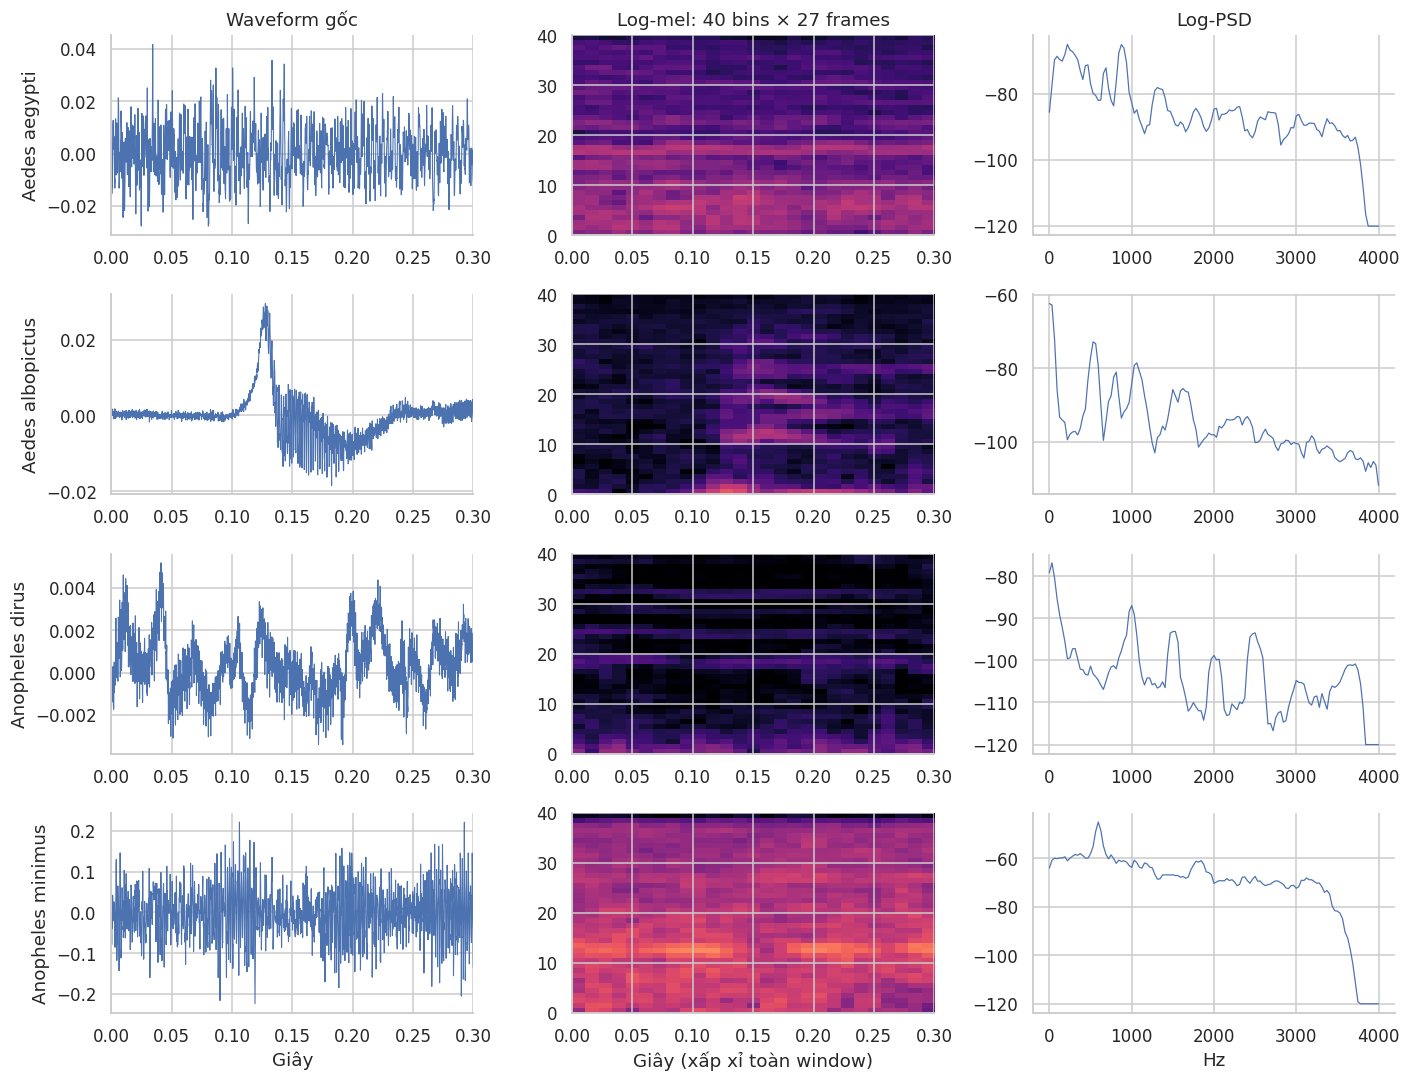

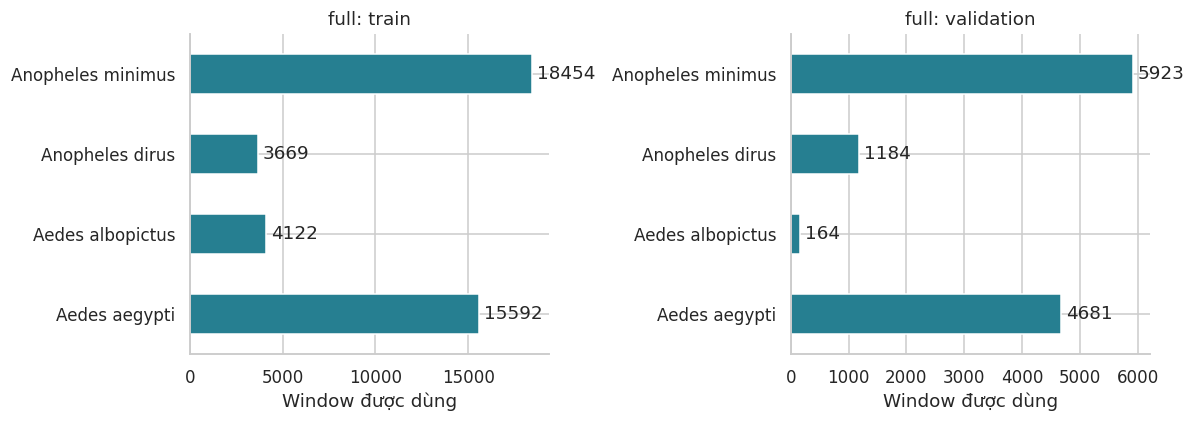

In [11]:
verify_cell_source('B_visuals')
fig,axes=plt.subplots(4,3,figsize=(13,10))
for label in LABELS:
    idx=int(np.flatnonzero(active['train'].label_id.to_numpy()==label)[0])
    row=active['train'].iloc[idx]; x=read_window(row)
    axes[label,0].plot(np.arange(len(x))/SAMPLE_RATE,x,lw=.7)
    axes[label,0].set_ylabel(LABEL_NAMES[label]); axes[label,0].set_xlim(0,.3)
    axes[label,1].imshow(arrays['train']['mel'][idx],origin='lower',aspect='auto',
        extent=[0,.3,0,MEL_BINS],vmin=-110,vmax=-20,cmap='magma')
    axes[label,2].plot(FREQUENCIES,arrays['train']['rf'][idx,:129],lw=.8)
for axis,title in zip(axes[0],['Waveform gốc','Log-mel: 40 bins × 27 frames','Log-PSD']): axis.set_title(title)
axes[-1,0].set_xlabel('Giây'); axes[-1,1].set_xlabel('Giây (xấp xỉ toàn window)'); axes[-1,2].set_xlabel('Hz')
save_figure('01_inputs')
fig,axes=plt.subplots(1,2,figsize=(11,4))
for axis,split in zip(axes,['train','validation']):
    counts=active[split].groupby('species').size().reindex(LABEL_NAMES)
    counts.plot.barh(ax=axis,color='#267f91'); axis.set_title(f'{RUN_MODE}: {split}')
    axis.set_xlabel('Window được dùng'); axis.set_ylabel('')
    axis.bar_label(axis.containers[0],padding=3)
save_figure('02_selected_windows')

## 7. Bốn kiến trúc kế thừa

Các mạng giữ channel/block của project cũ, nhận `[N,1,F,T]` thay bố trí `[N,1,T,F]` trước đây. TC-ResNet8 dùng F làm channel và convolution dọc thời gian; CNN-LSTM giảm trung bình trục F rồi đưa chuỗi T vào LSTM. Với 27 frame, CNN-LSTM còn 6 bước sau hai lần pooling. Không dùng trọng số cũ.

In [12]:
verify_cell_source('B_models_legacy')
def conv2(cin,cout,k=3,stride=1,groups=1):
    return nn.Sequential(nn.Conv2d(cin,cout,k,stride,k//2,groups=groups,bias=False),
                         nn.BatchNorm2d(cout),nn.ReLU())
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features=nn.Sequential(conv2(1,16),nn.MaxPool2d(2),conv2(16,32),
            nn.MaxPool2d(2),conv2(32,64))
        self.head=nn.Sequential(nn.Dropout(.2),nn.Linear(64,4))
    def forward(self,x): return self.head(self.features(x).mean((2,3)))
class DSCNN(nn.Module):
    def __init__(self):
        super().__init__(); layers=[conv2(1,32,stride=2)]
        for _ in range(4): layers.extend([conv2(32,32,groups=32),conv2(32,32,k=1)])
        self.features=nn.Sequential(*layers)
        self.head=nn.Sequential(nn.Dropout(.2),nn.Linear(32,4))
    def forward(self,x): return self.head(self.features(x).mean((2,3)))
class TemporalBlock(nn.Module):
    def __init__(self,cin,cout):
        super().__init__()
        self.main=nn.Sequential(nn.Conv1d(cin,cout,9,2,4,bias=False),nn.BatchNorm1d(cout),
            nn.ReLU(),nn.Conv1d(cout,cout,9,1,4,bias=False),nn.BatchNorm1d(cout))
        self.skip=nn.Sequential(nn.Conv1d(cin,cout,1,2,bias=False),nn.BatchNorm1d(cout))
    def forward(self,x): return torch.relu(self.main(x)+self.skip(x))
class TCResNet8(nn.Module):
    def __init__(self):
        super().__init__()
        self.features=nn.Sequential(nn.Conv1d(MEL_BINS,16,3,1,1,bias=False),nn.BatchNorm1d(16),
            nn.ReLU(),TemporalBlock(16,24),TemporalBlock(24,32),TemporalBlock(32,48))
        self.head=nn.Sequential(nn.Dropout(.2),nn.Linear(48,4))
    def forward(self,x): return self.head(self.features(x.squeeze(1)).mean(2))
class CNNLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.features=nn.Sequential(conv2(1,16),nn.MaxPool2d(2),conv2(16,32),nn.MaxPool2d(2))
        self.lstm=nn.LSTM(32,32,batch_first=True)
        self.head=nn.Sequential(nn.Dropout(.2),nn.Linear(32,4))
    def forward(self,x):
        sequence=self.features(x).mean(2).transpose(1,2)
        _,(hidden,_)=self.lstm(sequence)
        return self.head(hidden[-1])

## 8. Ba kiến trúc bổ sung: waveform, BC-ResNet-1 và MicroDSC-style

**MosquitoSong-style 1D:** ba lớp convolution có stride để học downsampling, hai block convolution/pooling và head nhỏ. Giữ ý tưởng từ paper nhưng dùng 16/32/64 channel và global pooling để hạn chế kích thước. Đây là biến thể tự triển khai, không phải MosquitoSong+ nguyên bản; chưa có noise/gain augmentation của paper.

**BC-ResNet-1:** theo cấu trúc tham chiếu Qualcomm: base channel 8, stage [2,2,4,4], SubSpectralNorm 5 nhóm, temporal dilation và classifier bốn lớp. Đầu vào 40 mel bins giữ hợp lệ các mức F=20→10→5. Recipe huấn luyện và độ dài đầu vào khác paper, phải ghi rõ. Nguồn: [code BC-ResNet](https://github.com/Qualcomm-AI-research/bcresnet), [MosquitoSong+](https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0310121).

<details><summary>Thông báo giấy phép cho phần BC-ResNet/SubSpectralNorm được thích nghi</summary>

Copyright (c) 2023 Qualcomm Technologies, Inc. All rights reserved.

Redistribution and use in source and binary forms, with or without modification, are permitted (subject to the limitations in the disclaimer below) provided that the following conditions are met:

* Redistributions of source code must retain the above copyright notice, this list of conditions and the following disclaimer:
* Redistributions in binary form must reproduce the above copyright notice, this list of conditions and the following disclaimer in the documentation and/or other materials provided with the distribution.
* Neither the name of Qualcomm Technologies, Inc. nor the names of its contributors may be used to endorse or promote products derived from this software without specific prior written permission.

NO EXPRESS OR IMPLIED LICENSES TO ANY PARTY'S PATENT RIGHTS ARE GRANTED BY THIS LICENSE. THIS SOFTWARE IS PROVIDED BY THE COPYRIGHT HOLDERS AND CONTRIBUTORS "AS IS" AND ANY EXPRESS OR IMPLIED WARRANTIES, INCLUDING, BUT NOT LIMITED TO, THE IMPLIED WARRANTIES OF MERCHANTABILITY AND FITNESS FOR A PARTICULAR PURPOSE ARE DISCLAIMED.

IN NO EVENT SHALL THE COPYRIGHT OWNER OR CONTRIBUTORS BE LIABLE FOR ANY DIRECT, INDIRECT, INCIDENTAL, SPECIAL, EXEMPLARY, OR CONSEQUENTIAL DAMAGES (INCLUDING, BUT NOT LIMITED TO, PROCUREMENT OF SUBSTITUTE GOODS OR SERVICES; LOSS OF USE, DATA, OR PROFITS; OR BUSINESS INTERRUPTION) HOWEVER CAUSED AND ON ANY THEORY OF LIABILITY, WHETHER IN CONTRACT, STRICT LIABILITY, OR TORT (INCLUDING NEGLIGENCE OR OTHERWISE) ARISING IN ANY WAY OUT OF THE USE OF THIS SOFTWARE, EVEN IF ADVISED OF THE POSSIBILITY OF SUCH DAMAGE.

</details>

**Enhanced MicroDSC-style:** tham khảo Kazeneza et al. (2026), [paper](https://doi.org/10.7717/peerj-cs.3925), [code v1.0.0](https://doi.org/10.5281/zenodo.18879243). Thiết kế PyTorch viết lại theo notebook training ở commit `8603867`: stem 16 kênh; ba block depthwise/pointwise 32/48/64, không bias convolution; ReLU6 sau depthwise và sau pointwise/BN; mỗi block có max-pooling 2×2; GAP, dropout 0,2 và head bốn lớp. Không thêm residual vì bản tham chiếu tắt nó. Ghi công Micheline Kazeneza và các đồng tác giả; nguồn v1.0.0 phát hành theo CC BY 4.0.

Bản này thay đầu vào 5 giây/16 kHz/MFE của nghiên cứu bằng log-mel chung **300 ms/8 kHz/40×27**. Không padding audio hoặc resize spectrogram. Stem giữ quy tắc TensorFlow SAME bằng padding bất đối xứng theo F; ba lần pooling VALID vẫn giữ được dữ liệu: **40×27 → 20×14 → 10×7 → 5×3 → 2×1**. BN dùng epsilon 0,001 và momentum PyTorch 0,01 (tương ứng moving-average momentum 0,99 của Keras); khởi tạo trọng số theo PyTorch, optimizer/early stopping/normalization theo recipe B. Head trả logits; softmax ở bước dự đoán. Chưa lượng tử hóa, chưa tái lập kết quả bài báo.

Mức giảm chiều thời gian khá mạnh; khả năng giữ thông tin phân loại phải đánh giá qua full validation và ablation ở C. Số tham số báo ở đây là **trainable parameters**, khác `Keras count_params()` có cả moving mean/variance của BN. Mục 9 sẽ hiển thị hai cách đếm để không nhầm với 7.483 của bản 11 lớp trong paper.


In [13]:
verify_cell_source('B_models_new')
class MosquitoSongStyle1D(nn.Module):
    def __init__(self):
        super().__init__()
        def block(cin,cout,k,stride=1):
            return nn.Sequential(nn.Conv1d(cin,cout,k,stride,k//2,bias=False),
                                 nn.BatchNorm1d(cout),nn.ReLU())
        self.features=nn.Sequential(block(1,16,9,2),block(16,16,7,2),block(16,32,5,2),
            block(32,32,5),nn.MaxPool1d(2),block(32,64,3),nn.MaxPool1d(2),nn.AdaptiveAvgPool1d(1))
        self.head=nn.Sequential(nn.Flatten(),nn.Linear(64,32),nn.ReLU(),nn.Dropout(.2),nn.Linear(32,4))
    def forward(self,x): return self.head(self.features(x))

# Adapted from Qualcomm-AI-research/bcresnet; full copyright/license in the markdown above.
class SubSpectralNorm(nn.Module):
    def __init__(self,channels,groups=5):
        super().__init__(); self.groups=groups; self.norm=nn.BatchNorm2d(channels*groups)
    def forward(self,x):
        n,c,f,t=x.shape
        assert f%self.groups==0
        return self.norm(x.reshape(n,c*self.groups,f//self.groups,t)).reshape(n,c,f,t)
class BCBlock(nn.Module):
    def __init__(self,cin,cout,stage,frequency_stride=1):
        super().__init__(); self.transition=cin!=cout
        self.project=conv2(cin,cout,k=1) if self.transition else nn.Identity()
        self.frequency=nn.Sequential(nn.Conv2d(cout,cout,(3,1),(frequency_stride,1),(1,0),
            groups=cout,bias=False),SubSpectralNorm(cout))
        dilation=2**stage
        self.temporal=nn.Sequential(nn.Conv2d(cout,cout,(1,3),padding=(0,dilation),
            dilation=(1,dilation),groups=cout,bias=False),nn.BatchNorm2d(cout),nn.SiLU(),
            nn.Conv2d(cout,cout,1,bias=False),nn.Dropout2d(.1))
    def forward(self,x):
        auxiliary=self.frequency(self.project(x))
        result=auxiliary+self.temporal(auxiliary.mean(2,keepdim=True))
        if not self.transition: result=result+x
        return torch.relu(result)
class BCResNet1(nn.Module):
    def __init__(self):
        super().__init__(); self.stem=nn.Sequential(nn.Conv2d(1,16,5,(2,1),2,bias=False),
                                                   nn.BatchNorm2d(16),nn.ReLU())
        layers=[]; cin=16
        for stage,(count,cout) in enumerate(zip([2,2,4,4],[8,12,16,20])):
            for i in range(count):
                layers.append(BCBlock(cin,cout,stage,2 if stage in (1,2) and i==0 else 1)); cin=cout
        self.blocks=nn.Sequential(*layers)
        self.head=nn.Sequential(nn.Conv2d(20,20,(5,5),padding=(0,2),groups=20,bias=False),
            nn.Conv2d(20,32,1,bias=False),nn.BatchNorm2d(32),nn.ReLU(),
            nn.AdaptiveAvgPool2d(1),nn.Conv2d(32,4,1),nn.Flatten())
    def forward(self,x): return self.head(self.blocks(self.stem(x)))
# Architecture reference: Kazeneza et al. (2026), Enhanced MicroDSC v1.0.0,
# CC BY 4.0, https://doi.org/10.5281/zenodo.18879243 (commit 8603867).
# Independent PyTorch adaptation: common B frontend, four logits, no paper checkpoint.
class MicroDSCBlock(nn.Module):
    def __init__(self,cin,cout):
        super().__init__()
        self.depthwise=nn.Conv2d(cin,cin,3,padding=1,groups=cin,bias=False)
        self.depthwise_activation=nn.ReLU6()
        self.pointwise=nn.Conv2d(cin,cout,1,bias=False)
        self.norm=nn.BatchNorm2d(cout,eps=1e-3,momentum=.01)
        self.activation=nn.ReLU6()
    def forward(self,x):
        x=self.depthwise_activation(self.depthwise(x))
        return self.activation(self.norm(self.pointwise(x)))

class MicroDSCStyle(nn.Module):
    def __init__(self):
        super().__init__()
        # TF SAME for kernel=3/stride=2 and F=40,T=27:
        # F pads 0 before/1 after; T pads 1 before/1 after.
        self.stem=nn.Sequential(nn.ZeroPad2d((1,1,0,1)),
            nn.Conv2d(1,16,3,stride=2,bias=False),
            nn.BatchNorm2d(16,eps=1e-3,momentum=.01),nn.ReLU6())
        self.stages=nn.Sequential(
            nn.Sequential(MicroDSCBlock(16,32),nn.MaxPool2d(2)),
            nn.Sequential(MicroDSCBlock(32,48),nn.MaxPool2d(2)),
            nn.Sequential(MicroDSCBlock(48,64),nn.MaxPool2d(2)))
        self.pool=nn.AdaptiveAvgPool2d(1)
        self.head=nn.Sequential(nn.Flatten(),nn.Dropout(.2),nn.Linear(64,4))
    def forward(self,x):
        return self.head(self.pool(self.stages(self.stem(x))))

FACTORIES=dict(small_cnn=SmallCNN,ds_cnn=DSCNN,tc_resnet8=TCResNet8,cnn_lstm=CNNLSTM,
    mosquitosong_style_1d=MosquitoSongStyle1D,bc_resnet1=BCResNet1,microdsc_style=MicroDSCStyle)
def make_model(name):
    seed_all(); return FACTORIES[name]().to(DEVICE)
def input_example(name,batch=1):
    return torch.zeros((batch,1,WINDOW_SAMPLES) if name=='mosquitosong_style_1d'
                       else (batch,1,MEL_BINS,TIME_FRAMES),device=DEVICE)
adaptations=dict(small_cnn='Old channels 16/32/64; 40×27 input; global pooling',
    ds_cnn='Old 32-channel stem and four DW/PW blocks; 40×27 input',
    tc_resnet8='Old [16,24,32,48]; 40 input channels; temporal axis 27, not frequency',
    cnn_lstm='Old CNN16/32 + LSTM32; six time steps after pooling',
    mosquitosong_style_1d='Inspired architecture: 16/32/64 channels, learned strided downsampling, global pooling; no paper recipe',
    bc_resnet1='BC-ResNet base8, SSN5, [2,2,4,4], four classes; 300ms; common B training recipe',
    microdsc_style='Enhanced MicroDSC-style v1.0.0: 16/32/48/64, ReLU6, BN eps1e-3/momentum0.01, TF SAME stem, 3 pools, GAP; common B frontend/recipe; PyTorch initialization; four classes, not paper reproduction')
assert set(FACTORIES)==set(NEURAL_MODELS)

## 9. Kiểm tra kích thước và thống kê chi phí kiến trúc

MAC chỉ đếm Conv1d/Conv2d, Linear và phép nhân ma trận chính của LSTM, mỗi tích nhân-cộng tính một MAC. Chưa gồm normalization, pooling, activation, residual cộng, frontend hoặc RF. `largest_module_output_bytes` là kích thước output module lớn nhất quan sát được với batch 1, **không phải peak RAM**. Trọng số thô FP32 khác kích thước file checkpoint và Flash/RAM của runtime thiết bị.

MicroDSC-style có bảng riêng theo dõi kích thước từng stage và đối chiếu cách đếm tham số. Sau pool cuối còn 2 dải tần × 1 bước thời gian, trước GAP; không có chiều nào bằng 0. Các con số này chưa chứng minh giữ đủ thông tin wingbeat hoặc vừa RAM thiết bị.

In [14]:
verify_cell_source('B_cost')
def architecture_cost(model,example):
    totals=dict(macs=0,largest_module_output_bytes=0)
    def hook(module,inputs,output):
        tensors=[]
        def collect(value):
            if torch.is_tensor(value): tensors.append(value)
            elif isinstance(value,(tuple,list)):
                for item in value: collect(item)
        collect(output)
        if tensors: totals['largest_module_output_bytes']=max(totals['largest_module_output_bytes'],
            sum(t.numel()*t.element_size() for t in tensors))
        if isinstance(module,(nn.Conv1d,nn.Conv2d)):
            totals['macs']+=output.numel()*(module.in_channels//module.groups)*int(np.prod(module.kernel_size))
        elif isinstance(module,nn.Linear): totals['macs']+=output.numel()*module.in_features
        elif isinstance(module,nn.LSTM):
            n,t,_=inputs[0].shape
            totals['macs']+=n*t*4*module.hidden_size*(module.input_size+module.hidden_size)
    handles=[m.register_forward_hook(hook) for m in model.modules() if len(list(m.children()))==0]
    model.eval()
    try:
        with torch.inference_mode(): result=model(example)
    finally:
        for handle in handles: handle.remove()
    assert result.shape==(1,4) and torch.isfinite(result).all()
    return totals
architecture_rows=[]
for name in NEURAL_MODELS:
    model=make_model(name); example=input_example(name)
    costs=architecture_cost(model,example)
    architecture_rows.append(dict(model=name,input_shape=str(tuple(example.shape)),
        parameters=sum(p.numel() for p in model.parameters()),
        raw_weight_bytes=sum(p.numel()*p.element_size() for p in model.parameters()),
        **costs,adaptation=adaptations[name],module_repr=str(model)))
architectures=save_table(pd.DataFrame(architecture_rows),'architectures')
display(architectures.drop(columns='module_repr'))

microdsc=make_model('microdsc_style').eval()
microdsc_shape_rows=[]
with torch.inference_mode():
    x=input_example('microdsc_style')
    microdsc_shape_rows.append(dict(stage='input',shape=str(tuple(x.shape)),frequency=40,time=27))
    x=microdsc.stem(x)
    microdsc_shape_rows.append(dict(stage='stem',shape=str(tuple(x.shape)),frequency=x.shape[-2],time=x.shape[-1]))
    for i,stage in enumerate(microdsc.stages,1):
        x=stage(x)
        microdsc_shape_rows.append(dict(stage=f'block{i} + pool',shape=str(tuple(x.shape)),frequency=x.shape[-2],time=x.shape[-1]))
    x=microdsc.pool(x)
    microdsc_shape_rows.append(dict(stage='global average pool',shape=str(tuple(x.shape)),frequency=x.shape[-2],time=x.shape[-1]))
    logits=microdsc.head(x)
    assert logits.shape==(1,4) and torch.isfinite(logits).all()
microdsc_shapes=save_table(pd.DataFrame(microdsc_shape_rows),'microdsc_layer_shapes')
assert list(zip(microdsc_shapes.frequency,microdsc_shapes.time))==[(40,27),(20,14),(10,7),(5,3),(2,1),(1,1)]
microdsc_trainable=sum(p.numel() for p in microdsc.parameters())
microdsc_bn_statistics=sum(m.running_mean.numel()+m.running_var.numel()
    for m in microdsc.modules() if isinstance(m,nn.BatchNorm2d))
microdsc_counts=save_table(pd.DataFrame([
    dict(item='B: trainable parameters, 4 classes',value=microdsc_trainable),
    dict(item='B: BN moving mean/variance elements (not trainable)',value=microdsc_bn_statistics),
    dict(item='B: trainable + BN moving statistics, 4 classes',value=microdsc_trainable+microdsc_bn_statistics),
    dict(item='Reference: Keras total, 11 classes',value=7483),
    dict(item='B: trainable + BN statistics, with 11-class head for count comparison only',
         value=microdsc_trainable+microdsc_bn_statistics+(11-4)*(64+1))]),'microdsc_parameter_counts')
assert microdsc_counts.iloc[-1].value==7483
microdsc_reference=save_table(pd.DataFrame([
    dict(item='paper',value='https://doi.org/10.7717/peerj-cs.3925'),
    dict(item='code_version',value='v1.0.0 / commit 8603867'),
    dict(item='code_archive',value='https://doi.org/10.5281/zenodo.18879243'),
    dict(item='reference_training_notebook',value='https://github.com/micheline24/enhanced_microdsc/blob/8603867/training/models_training.ipynb'),
    dict(item='reference_training_sha256',value='cdf303981d12f057ed27bc1e9ee00ed7c4e14aa5abb78232633239eabff2e7cb'),
    dict(item='attribution',value='Micheline Kazeneza and coauthors (2026); source archive CC BY 4.0'),
    dict(item='scope',value='Independent PyTorch adaptation, common 300ms B log-mel; four classes; no pretrained weights, quantization or paper-score reproduction')]),'microdsc_reference')
display(microdsc_shapes); display(microdsc_counts)


,model,input_shape,parameters,raw_weight_bytes,macs,largest_module_output_bytes,adaptation
0,small_cnn,"(1, 1, 40, 27)",23668,94672,2459776,69120,Old channels 16/32/64; 40×27 input; global poo...
1,ds_cnn,"(1, 1, 40, 27)",6244,24976,1550208,35840,Old 32-channel stem and four DW/PW blocks; 40×...
2,tc_resnet8,"(1, 1, 40, 27)",64788,259152,441024,1728,"Old [16,24,32,48]; 40 input channels; temporal..."
3,cnn_lstm,"(1, 1, 40, 27)",13428,53712,1402880,69120,Old CNN16/32 + LSTM32; six time steps after po...
4,mosquitosong_style_1d,"(1, 1, 2400)",18292,73168,4475776,76800,"Inspired architecture: 16/32/64 channels, lear..."
5,bc_resnet1,"(1, 1, 40, 27)",8968,35872,663572,34560,"BC-ResNet base8, SSN5, [2,2,4,4], four classes..."
6,microdsc_style,"(1, 1, 40, 27)",6708,26832,404496,35840,"Enhanced MicroDSC-style v1.0.0: 16/32/48/64, R..."


,stage,shape,frequency,time
0,input,"(1, 1, 40, 27)",40,27
1,stem,"(1, 16, 20, 14)",20,14
2,block1 + pool,"(1, 32, 10, 7)",10,7
3,block2 + pool,"(1, 48, 5, 3)",5,3
4,block3 + pool,"(1, 64, 2, 1)",2,1
5,global average pool,"(1, 64, 1, 1)",1,1


,item,value
0,"B: trainable parameters, 4 classes",6708
1,B: BN moving mean/variance elements (not train...,320
2,"B: trainable + BN moving statistics, 4 classes",7028
3,"Reference: Keras total, 11 classes",7483
4,"B: trainable + BN statistics, with 11-class he...",7483


## 10. Loader, tổng hợp cấp clip và metric

Loader không chứa test, không dùng metadata làm feature. Các biến đổi đã fit chỉ dùng training. Clip score lấy trung bình softmax/probability của những window thuộc clip. Theo domain chỉ báo support/accuracy và recall theo loài–domain; không so macro-F1 của một domain thiếu lớp như bài phân biệt đủ bốn loài.

In [15]:
verify_cell_source('B_evaluation')
class WindowDataset(Dataset):
    def __init__(self,split,waveform=False):
        assert split in active and split!='test'
        self.split=split; self.frame=active[split]; self.waveform=waveform
    def __len__(self): return len(self.frame)
    def __getitem__(self,index):
        if self.waveform:
            x=np.asarray(arrays[self.split]['waveform'][index],dtype=np.float32)
            x=((x-float(statistics['raw_mean']))/float(statistics['raw_std'])).astype(np.float32)[None,:]
        else:
            x=np.asarray(arrays[self.split]['mel'][index],dtype=np.float32)
            x=((x-statistics['mel_mean'][:,None])/statistics['mel_std'][:,None])[None,:,:]
        return torch.from_numpy(np.array(x,dtype=np.float32,copy=True)),int(self.frame.iloc[index].label_id)
def make_loader(name,split,shuffle=False,generator=None):
    batch=SMOKE_BATCH_SIZE if RUN_MODE=='smoke' else BATCH_SIZE
    if generator is None: generator=torch.Generator().manual_seed(SEED+1)
    return DataLoader(WindowDataset(split,name=='mosquitosong_style_1d'),batch_size=batch,
        shuffle=shuffle,num_workers=0,drop_last=False,generator=generator)
def clip_probabilities(frame,probabilities):
    probabilities=np.asarray(probabilities,dtype=np.float64)
    assert probabilities.shape==(len(frame),4) and np.isfinite(probabilities).all()
    assert np.allclose(probabilities.sum(1),1,atol=1e-5)
    tmp=frame[['window_id','clip_id','label_id','species','domain','leakage_group']].copy()
    for i in LABELS: tmp[f'p{i}']=probabilities[:,i]
    assert tmp.groupby('clip_id').label_id.nunique().eq(1).all()
    aggregate=tmp.groupby('clip_id',sort=True).agg(label_id=('label_id','first'),
        species=('species','first'),domain=('domain','first'),leakage_group=('leakage_group','first'),
        windows=('window_id','size'),**{f'p{i}':(f'p{i}','mean') for i in LABELS}).reset_index()
    aggregate['prediction']=aggregate[[f'p{i}' for i in LABELS]].to_numpy().argmax(1)
    return aggregate
def basic_metrics(y,probabilities):
    pred=np.asarray(probabilities).argmax(1)
    precision,recall,f1,support=precision_recall_fscore_support(y,pred,labels=LABELS,zero_division=0)
    return dict(macro_f1=float(f1.mean()),balanced_accuracy=float(recall[support>0].mean()),
        accuracy=float(np.mean(pred==np.asarray(y))),precision=precision,recall=recall,f1=f1,support=support,
        confusion=confusion_matrix(y,pred,labels=LABELS))
@torch.inference_mode()
def predict_neural(model,name,split):
    model.eval(); outputs=[]; loss_sum=0.; count=0
    loader=make_loader(name,split)
    print(f'{name}: {split} bắt đầu ({len(loader)} batch)',flush=True)
    for step,(x,y) in enumerate(loader):
        logits=model(x.to(DEVICE)); loss=nn.functional.cross_entropy(logits,y.to(DEVICE),reduction='sum')
        outputs.append(torch.softmax(logits,1).cpu().numpy()); loss_sum+=float(loss); count+=len(y)
        if step==0 or (step+1)%100==0 or step+1==len(loader):
            print(f'{name}: {split} batch {step+1}/{len(loader)}',flush=True)
    return np.concatenate(outputs),loss_sum/count
def validation_score(frame,probabilities):
    aggregate=clip_probabilities(frame,probabilities)
    return f1_score(aggregate.label_id,aggregate.prediction,labels=LABELS,average='macro',zero_division=0)
metric_rows=[]; per_class_rows=[]; domain_rows=[]; predictions={}; diagnostic_rows=[]
def record_predictions(name,split,probabilities):
    frame=active[split]; aggregate=clip_probabilities(frame,probabilities)
    probabilities=np.asarray(probabilities)
    levels={'window':basic_metrics(frame.label_id,probabilities),
            'clip':basic_metrics(aggregate.label_id,aggregate[[f'p{i}' for i in LABELS]].to_numpy())}
    for level,result in levels.items():
        metric_rows.append(dict(mode=RUN_MODE,model=name,split=split,level=level,
            examples=len(frame) if level=='window' else len(aggregate),
            **{k:result[k] for k in ['macro_f1','balanced_accuracy','accuracy']}))
        for i in LABELS:
            per_class_rows.append(dict(mode=RUN_MODE,model=name,split=split,level=level,
                species=LABEL_NAMES[i],precision=result['precision'][i],recall=result['recall'][i],
                f1=result['f1'][i],support=int(result['support'][i])))
    for (species,domain),part in aggregate.groupby(['species','domain']):
        domain_rows.append(dict(mode=RUN_MODE,model=name,split=split,species=species,domain=domain,
            clips=len(part),recall=float(part.prediction.eq(part.label_id).mean())))
    if split=='validation':
        aggregate.insert(0,'model',name); aggregate.insert(0,'mode',RUN_MODE)
        save_table(aggregate,f'{name}_validation_clips')
        wp=frame[['window_id','clip_id','label_id','domain']].copy()
        wp['prediction']=probabilities.argmax(1)
        for i in LABELS: wp[f'p{i}']=probabilities[:,i]
        wp.insert(0,'model',name); wp.insert(0,'mode',RUN_MODE)
        save_table(wp,f'{name}_validation_windows')
        predictions[name]=aggregate
    return levels['clip']

## 11. Mốc majority và Random Forest

Majority dựa trên số window training của lần chạy; nếu bằng nhau chọn label ID nhỏ hơn. RF có 100 cây, depth tối đa 10, không class weight. Imputer median fit trong pipeline trên train; feature thiếu hoàn toàn vẫn giữ cột. Thống kê cây/node và thời gian được ghi riêng. File joblib chỉ được nạp từ kết quả local do notebook tạo.

In [16]:
verify_cell_source('B_rf')
majority_label=int(np.bincount(active['train'].label_id,minlength=4).argmax())
for split,frame in active.items():
    p=np.zeros((len(frame),4)); p[:,majority_label]=1
    record_predictions('majority',split,p)
rf=Pipeline([('imputer',SimpleImputer(strategy='median',keep_empty_features=True)),
    ('classifier',RandomForestClassifier(n_estimators=RF_TREES,max_depth=RF_MAX_DEPTH,
         random_state=SEED,class_weight=None,n_jobs=CPU_THREADS))])
rf_folder=MODEL_DIR/'spectral_rf'; rf_folder.mkdir(exist_ok=True)
rf_path=rf_folder/'model.joblib'; rf_metadata=rf_folder/'identity.csv'
reuse=False
if rf_path.exists() and rf_metadata.exists():
    old=pd.read_csv(rf_metadata,keep_default_na=False).iloc[0]
    reuse=old.run_id==RUN_ID and old.sha256==sha(rf_path)
if reuse:
    rf=joblib.load(rf_path); rf_fit_seconds=float(old.fit_seconds)
else:
    started=time.perf_counter()
    with threadpool_limits(limits=CPU_THREADS): rf.fit(arrays['train']['rf'],active['train'].label_id)
    rf_fit_seconds=time.perf_counter()-started
    joblib.dump(rf,rf_path)
    pd.DataFrame([dict(run_id=RUN_ID,sha256=sha(rf_path),fit_seconds=rf_fit_seconds)]).to_csv(rf_metadata,index=False)
if not reuse: sync_model('spectral_rf',1)
assert list(rf.classes_)==list(LABELS)
for split in active:
    with threadpool_limits(limits=CPU_THREADS): p=rf.predict_proba(arrays[split]['rf'])
    record_predictions('spectral_rf',split,p)
rf_stats=dict(model='spectral_rf',trees=len(rf['classifier'].estimators_),
    nodes=sum(t.tree_.node_count for t in rf['classifier'].estimators_),
    max_depth=max(t.tree_.max_depth for t in rf['classifier'].estimators_),
    artifact_bytes=rf_path.stat().st_size,fit_seconds=rf_fit_seconds)
save_table(pd.DataFrame([rf_stats]),'rf_cost')
display(pd.DataFrame([rf_stats]))

,model,trees,nodes,max_depth,artifact_bytes,fit_seconds
0,spectral_rf,100,57976,10,5609746,40.365275


## 12. Vòng huấn luyện, early stopping và resume

Mọi neural model dùng Adam + cross-entropy không weight. Checkpoint tốt nhất theo validation clip macro-F1; hòa điểm giữ epoch sớm hơn. Epoch smoke giới hạn hai batch nên không phải epoch đi hết dữ liệu.

`last.pt` lưu model/optimizer, epoch, lịch sử, best score, RNG và generator của loader để tiếp tục lượt bị ngắt. `best.pt` giữ model được chọn cùng thống kê tiền xử lý. Checkpoint có run identity: thay dữ liệu/recipe/source sẽ không được tái sử dụng. Chỉ nạp checkpoint local của notebook, không nạp file không rõ nguồn.

Lưu checkpoint dùng thay thế file nguyên tử; nếu Windows khóa file tạm thời, thử lại tối đa sáu lần với khoảng chờ ngắn. Nếu vẫn lỗi thì báo lỗi và giữ checkpoint trước đó, không tiếp tục như đã lưu thành công.

In [17]:
verify_cell_source('B_training')

def atomic_torch_save(value,path):
    tmp=path.with_suffix(path.suffix+'.tmp');torch.save(value,tmp)
    for attempt in range(6):
        try: os.replace(tmp,path);return
        except PermissionError:
            if attempt==5:raise
            time.sleep(.05*2**attempt)

def read_local_checkpoint(path):
    # CPU mapping keeps RNG byte tensors on CPU, even when the model trains on CUDA.
    result=torch.load(path,map_location='cpu',weights_only=True)
    assert result['run_id']==RUN_ID and result['mode']==RUN_MODE,'Checkpoint khác run identity'
    assert result.get('format_version')==2,'Checkpoint format không phù hợp'
    return result

def rng_state(generator):
    state=np.random.get_state()
    return dict(python=random.getstate(),numpy=[state[0],state[1].tolist(),state[2],state[3],state[4]],
        torch=torch.get_rng_state(),loader=generator.get_state(),
        cuda=torch.cuda.get_rng_state_all() if DEVICE.type=='cuda' else [])

def restore_rng(state,generator):
    random.setstate(state['python']);n=state['numpy']
    np.random.set_state((n[0],np.asarray(n[1],dtype=np.uint32),n[2],n[3],n[4]))
    torch.set_rng_state(state['torch'].cpu());generator.set_state(state['loader'].cpu())
    if DEVICE.type=='cuda':
        assert len(state['cuda'])==torch.cuda.device_count(),'Số GPU khác checkpoint'
        torch.cuda.set_rng_state_all([v.cpu() for v in state['cuda']])

def train_neural(name):
    folder=MODEL_DIR/name;folder.mkdir(exist_ok=True)
    last_path,best_path=folder/'last.pt',folder/'best.pt'
    model=make_model(name);optimizer=torch.optim.Adam(model.parameters(),lr=LEARNING_RATE)
    generator=torch.Generator().manual_seed(SEED)
    train_loader=make_loader(name,'train',True,generator)
    epochs=SMOKE_EPOCHS if RUN_MODE=='smoke' else MAX_EPOCHS
    history=[];start_epoch=0;best_score=-np.inf;best_epoch=0;bad_epochs=0;train_seconds=0.;completed=False;best_weights=None
    if last_path.exists():
        candidate=read_local_checkpoint(last_path)
        assert candidate['model_name']==name
        model.load_state_dict(candidate['model']);optimizer.load_state_dict(candidate['optimizer'])
        history=candidate['history'];start_epoch=candidate['next_epoch']
        best_score=candidate['best_score'];best_epoch=candidate['best_epoch'];best_weights=candidate['best_model']
        bad_epochs=candidate['bad_epochs'];train_seconds=candidate['train_seconds'];completed=candidate['completed']
        restore_rng(candidate['rng'],generator)
        print(name,'resume:',start_epoch,'epoch; completed=',completed,flush=True)
    def best_payload():
        return dict(format_version=2,run_id=RUN_ID,mode=RUN_MODE,model_name=name,model=best_weights,
            selected_epoch=best_epoch,validation_clip_macro_f1=best_score,
            normalization={k:np.asarray(v).tolist() for k,v in statistics.items()},
            frontend=frontend_settings,label_names=LABEL_NAMES)
    for epoch in range(start_epoch,epochs):
        if completed:break
        print(f'{name}: epoch {epoch+1}/{epochs} train bắt đầu ({len(train_loader)} batch)',flush=True)
        model.train()
        if DEVICE.type=='cuda':torch.cuda.synchronize(DEVICE)
        started=time.perf_counter();loss_sum=0.;seen=0;updates=0
        before=next(model.parameters()).detach().clone()
        for step,(x,y) in enumerate(train_loader):
            if RUN_MODE=='smoke' and step>=SMOKE_MAX_BATCHES:break
            optimizer.zero_grad(set_to_none=True)
            logits=model(x.to(DEVICE));loss=nn.functional.cross_entropy(logits,y.to(DEVICE))
            assert torch.isfinite(loss)
            loss.backward()
            if RUN_MODE=='smoke' or step==0:
                assert all(torch.isfinite(p.grad).all() for p in model.parameters() if p.grad is not None)
            optimizer.step();loss_sum+=float(loss.detach())*len(y);seen+=len(y);updates+=1
            if step==0 or (step+1)%100==0 or step+1==len(train_loader):
                print(f'{name}: epoch {epoch+1}/{epochs} train batch {step+1}/{len(train_loader)}',flush=True)
        assert updates>0 and not torch.equal(before,next(model.parameters()).detach()),'Không cập nhật trọng số'
        p,val_loss=predict_neural(model,name,'validation');score=float(validation_score(active['validation'],p))
        if DEVICE.type=='cuda':torch.cuda.synchronize(DEVICE)
        seconds=time.perf_counter()-started;train_seconds+=seconds
        history.append(dict(epoch=epoch+1,train_loss=loss_sum/seen,validation_loss=val_loss,
            validation_clip_macro_f1=score,windows_seen=seen,updates=updates,seconds=seconds))
        improved=score>best_score+1e-12
        if improved:
            best_score=score;best_epoch=epoch+1;bad_epochs=0;best_weights=copy.deepcopy(model.state_dict())
        else:bad_epochs+=1
        completed=epoch+1>=epochs or bad_epochs>=PATIENCE
        # Last is self-contained: selected weights are included if saving best.pt is interrupted.
        atomic_torch_save(dict(format_version=2,run_id=RUN_ID,mode=RUN_MODE,model_name=name,
            model=model.state_dict(),best_model=best_weights,optimizer=optimizer.state_dict(),
            next_epoch=epoch+1,history=history,best_score=best_score,best_epoch=best_epoch,
            bad_epochs=bad_epochs,train_seconds=train_seconds,completed=completed,rng=rng_state(generator)),last_path)
        if improved:atomic_torch_save(best_payload(),best_path)
        save_table(pd.DataFrame(history).assign(model=name,mode=RUN_MODE),name+'_history')
        sync_model(name,epoch+1)
        print(f'{name}: epoch {epoch+1}/{epochs}, loss={loss_sum/seen:.4f}, val clip F1={score:.4f}',flush=True)
        if completed:
            reason='đạt số epoch tối đa' if epoch+1>=epochs else f'early stopping: {PATIENCE} epoch không cải thiện'
            print(f'{name}: {reason}; chọn epoch {best_epoch}, F1={best_score:.4f}',flush=True)
            break
    assert best_weights is not None and [h['epoch'] for h in history]==list(range(1,len(history)+1))
    best_ok=False
    if best_path.exists():
        try:
            best=read_local_checkpoint(best_path)
            best_ok=best['model_name']==name and best['selected_epoch']==best_epoch
        except (OSError,RuntimeError,ValueError,EOFError,pickle.UnpicklingError):pass
    if not best_ok:
        atomic_torch_save(best_payload(),best_path);sync_model(name,len(history))
    best=read_local_checkpoint(best_path);model.load_state_dict(best['model']);model.eval()
    save_table(pd.DataFrame(history).assign(model=name,mode=RUN_MODE),name+'_history')
    return model,dict(model=name,epochs_run=len(history),best_epoch=best_epoch,
        updates=sum(h['updates'] for h in history),fit_seconds=train_seconds,
        best_model_bytes=best_path.stat().st_size,best_model_sha256=sha(best_path),
        state=RUN_MODE+'_complete')


## 13. Chạy sáu neural model trong chế độ đã chọn

Mặc định chỉ smoke: 2 epoch × tối đa 2 batch/model. Kiểm tra forward/backward trên window thật, loss/gradient hữu hạn và trọng số thay đổi. Đánh giá train/validation bằng checkpoint được chọn; nạp lại checkpoint và so xác suất để kiểm tra serialization. Chưa chạy test.

In [18]:
verify_cell_source('B_run')
trained_models={}; training_rows=[]; histories={}; serialization_checks=[]
for name in NEURAL_MODELS:
    print('Bắt đầu:',name,'| mode:',RUN_MODE,flush=True)
    model,info=train_neural(name)
    trained_models[name]=model; training_rows.append(info)
    histories[name]=pd.read_csv(TABLES/f'{name}_history.csv')
    for split in active:
        p,loss=predict_neural(model,name,split)
        record_predictions(name,split,p)
        diagnostic_rows.append(dict(model=name,split=split,loss=loss,mode=RUN_MODE))
        if split=='validation':
            reloaded=make_model(name)
            reloaded.load_state_dict(read_local_checkpoint(MODEL_DIR/name/'best.pt')['model'])
            q,_=predict_neural(reloaded,name,split)
            serialization_checks.append(dict(model=name,passed=bool(np.allclose(p,q,atol=1e-7))))
training_summary=save_table(pd.DataFrame(training_rows),'training_summary')
save_table(pd.DataFrame(diagnostic_rows),'selected_model_losses')
save_table(pd.DataFrame(serialization_checks),'checkpoint_roundtrip')
assert all(r['passed'] for r in serialization_checks)
display(training_summary)

Bắt đầu: small_cnn | mode: full
small_cnn resume: 19 epoch; completed= True
small_cnn: train bắt đầu (654 batch)
small_cnn: train batch 1/654
small_cnn: train batch 100/654
small_cnn: train batch 200/654
small_cnn: train batch 300/654
small_cnn: train batch 400/654
small_cnn: train batch 500/654
small_cnn: train batch 600/654
small_cnn: train batch 654/654
small_cnn: validation bắt đầu (187 batch)
small_cnn: validation batch 1/187
small_cnn: validation batch 100/187
small_cnn: validation batch 187/187
small_cnn: validation bắt đầu (187 batch)
small_cnn: validation batch 1/187
small_cnn: validation batch 100/187
small_cnn: validation batch 187/187
Bắt đầu: ds_cnn | mode: full
ds_cnn resume: 11 epoch; completed= True
ds_cnn: train bắt đầu (654 batch)
ds_cnn: train batch 1/654
ds_cnn: train batch 100/654
ds_cnn: train batch 200/654
ds_cnn: train batch 300/654
ds_cnn: train batch 400/654
ds_cnn: train batch 500/654
ds_cnn: train batch 600/654
ds_cnn: train batch 654/654
ds_cnn: validation 

,model,epochs_run,best_epoch,updates,fit_seconds,best_model_bytes,best_model_sha256,state
0,small_cnn,19,11,12426,167.251751,108573,d3341d249f542fcd4424ab2e3fd305043b4bc51e10ec97...,full_complete
1,ds_cnn,11,3,7194,109.767603,51949,216d6cd0f85fdbeeaca311d381755cef6a025f181b17e1...,full_complete
2,tc_resnet8,12,4,7848,123.613271,288069,7a5646c9b9c17c0054401acc4fac683efcd3919d37660b...,full_complete
3,cnn_lstm,10,2,6540,91.722200,65801,cd177e821d8abb200061a6af1cff414f4db720acfd1f4c...,full_complete
4,mosquitosong_style_1d,13,5,8502,136.749288,91581,492d1ea18f7b51a40825a44312c3f1c7488efb0adc48e5...,full_complete
5,bc_resnet1,13,5,8502,250.329240,117305,36bab39217134a26eaa3aaf5e9b6335e1976e306bab0e9...,full_complete
6,microdsc_style,13,5,8502,110.898942,44108,f0c4613f82d5fcbcb50b7991d7ce07fdb3f95420069b43...,full_complete


## 14. Bảng kết quả và biểu đồ

Trong smoke, bảng/biểu đồ vẫn được tạo để kiểm tra đường report, nhưng **không có bảng xếp hạng hoặc kết luận model thắng**. Khi chạy full, bảng so sánh cấp clip là đầu ra chính; một seed và validation albopictus một nguồn vẫn chưa đủ để khẳng định thứ hạng ổn định.

,mode,model,split,level,examples,macro_f1,balanced_accuracy,accuracy
3,full,majority,validation,clip,211,0.151815,0.250000,0.436019
11,full,small_cnn,validation,clip,211,0.647539,0.733696,0.654028
15,full,ds_cnn,validation,clip,211,0.647539,0.733696,0.654028
19,full,tc_resnet8,validation,clip,211,0.639500,0.736413,0.658768
23,full,cnn_lstm,validation,clip,211,0.647539,0.733696,0.654028
7,full,spectral_rf,validation,clip,211,0.642283,0.724767,0.649289
27,full,mosquitosong_style_1d,validation,clip,211,0.642283,0.724767,0.649289
31,full,bc_resnet1,validation,clip,211,0.653244,0.736413,0.658768
35,full,microdsc_style,validation,clip,211,0.647539,0.733696,0.654028


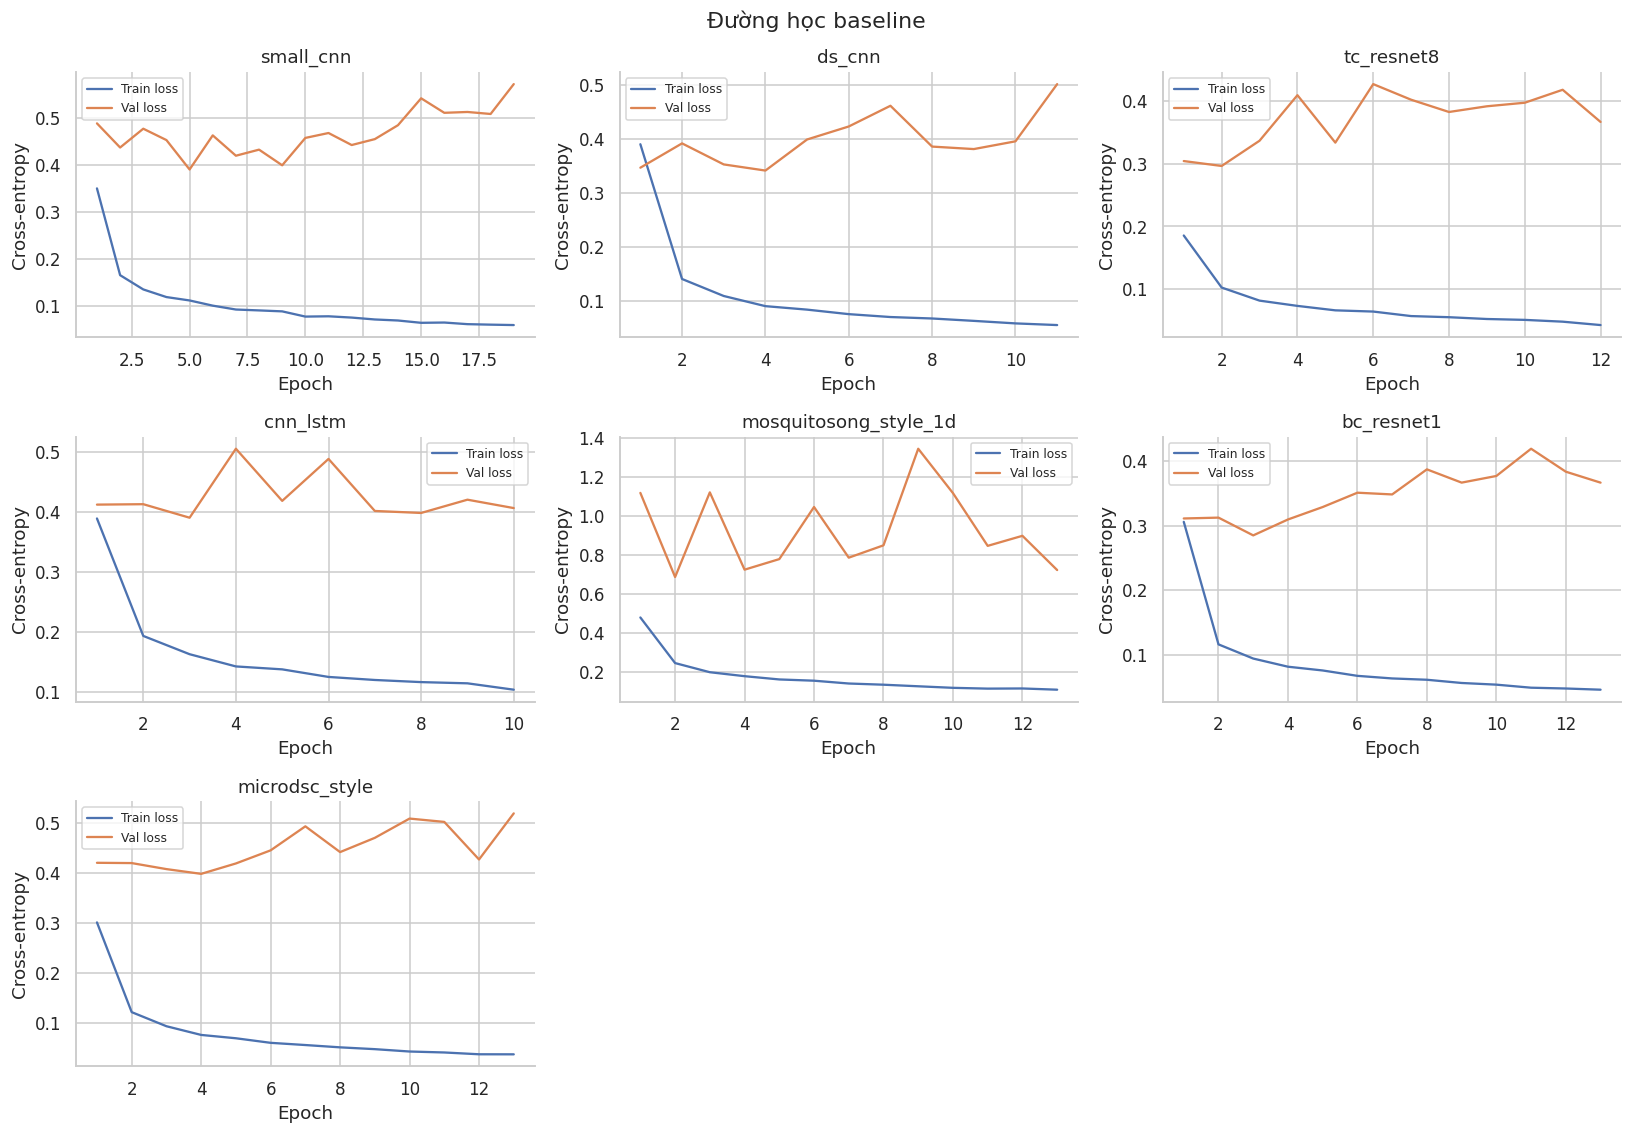

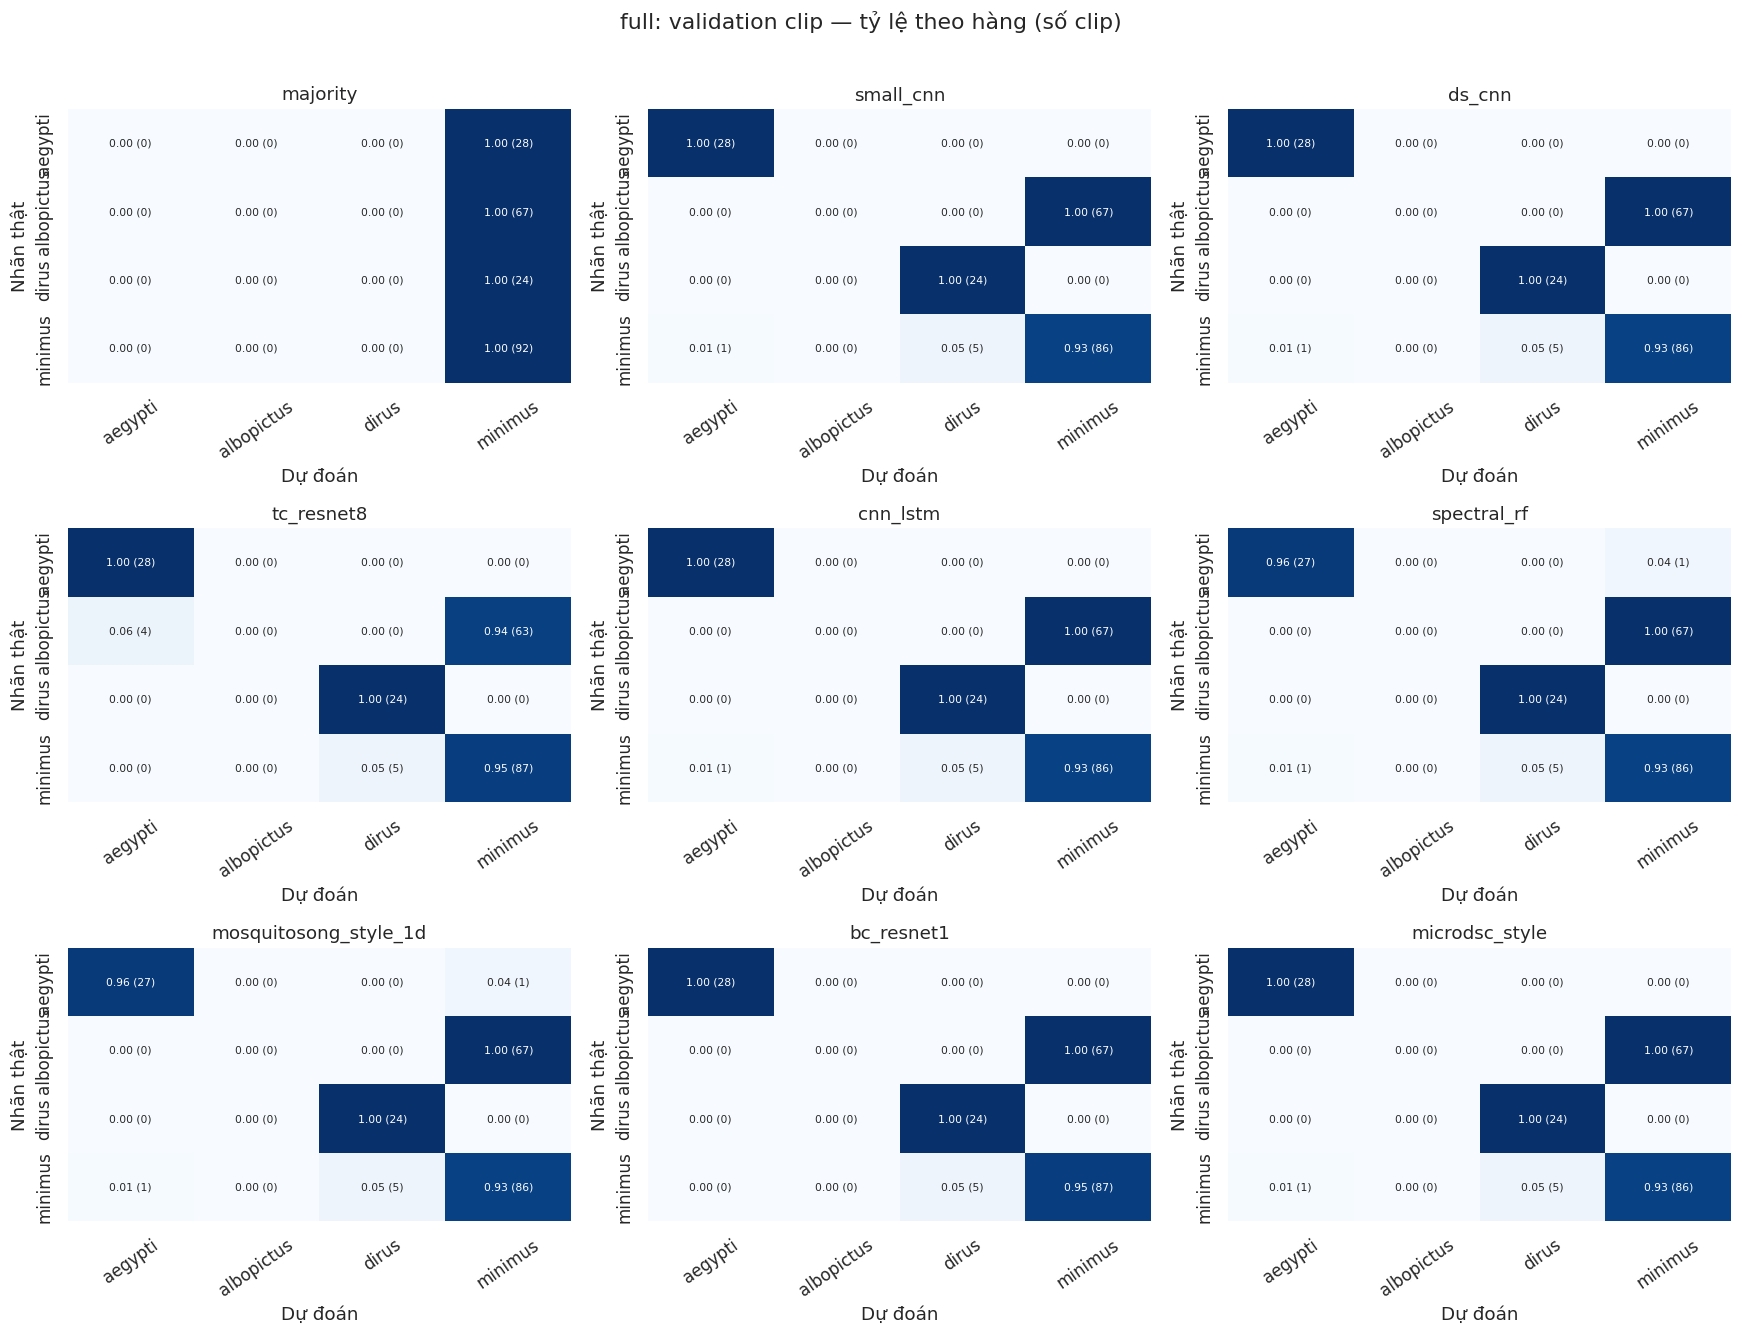

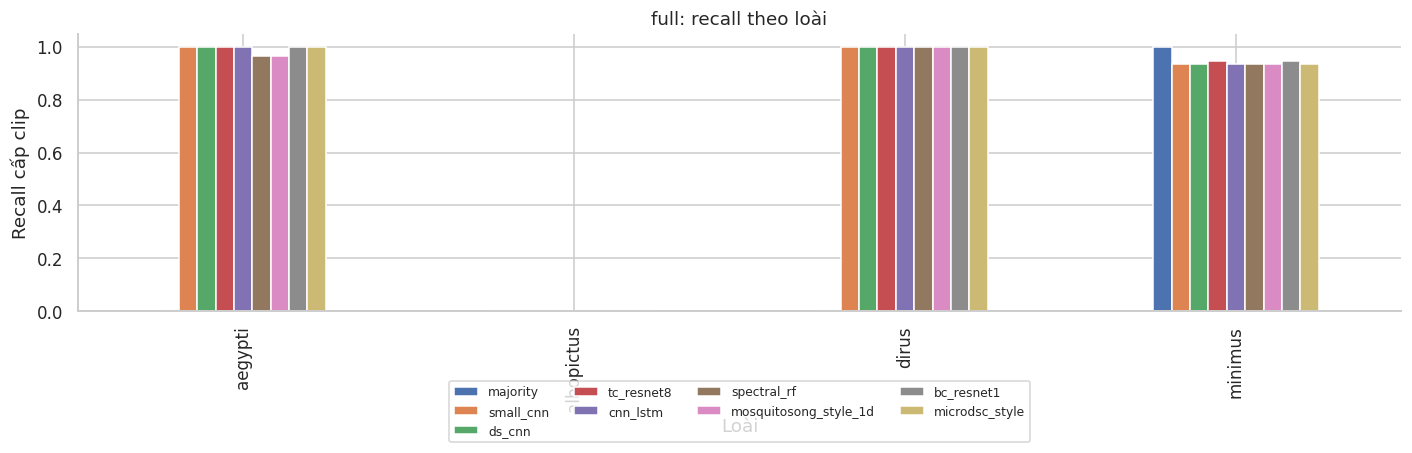

In [19]:
verify_cell_source('B_results')
metrics=save_table(pd.DataFrame(metric_rows),'metrics')
per_class=save_table(pd.DataFrame(per_class_rows),'per_class_metrics')
domain_metrics=save_table(pd.DataFrame(domain_rows),'species_domain_recall')
val_metrics=metrics.loc[metrics.split.eq('validation')&metrics.level.eq('clip')].copy()
val_metrics['model']=pd.Categorical(val_metrics.model,['majority',*MODELS],ordered=True)
val_metrics=val_metrics.sort_values('model')
display(val_metrics)
learning_cols=3
learning_rows=(len(NEURAL_MODELS)+learning_cols-1)//learning_cols
fig,axes=plt.subplots(learning_rows,learning_cols,figsize=(15,3.5*learning_rows),squeeze=False)
for axis,name in zip(axes.flat,NEURAL_MODELS):
    h=histories[name]
    axis.plot(h.epoch,h.train_loss,label='Train loss'); axis.plot(h.epoch,h.validation_loss,label='Val loss')
    axis.set_title(name); axis.set_xlabel('Epoch'); axis.set_ylabel('Cross-entropy'); axis.legend(fontsize=8)
for axis in axes.flat[len(NEURAL_MODELS):]: axis.set_visible(False)
fig.suptitle(f'{RUN_MODE}: đường học — smoke chỉ kiểm tra code' if RUN_MODE=='smoke' else 'Đường học baseline')
save_figure('03_learning_curves')
short_names=['aegypti','albopictus','dirus','minimus']
confusion_names=['majority',*MODELS]
confusion_cols=3
confusion_rows=(len(confusion_names)+confusion_cols-1)//confusion_cols
fig,axes=plt.subplots(confusion_rows,confusion_cols,figsize=(16,4*confusion_rows),squeeze=False)
for axis,name in zip(axes.flat,confusion_names):
    part=predictions[name]
    counts=confusion_matrix(part.label_id,part.prediction,labels=LABELS)
    normalized=counts/np.maximum(counts.sum(1,keepdims=True),1)
    annotation=np.array([[f'{normalized[i,j]:.2f} ({counts[i,j]})' for j in LABELS] for i in LABELS])
    sns.heatmap(normalized,annot=annotation,fmt='',vmin=0,vmax=1,cmap='Blues',cbar=False,ax=axis,
        xticklabels=short_names,yticklabels=short_names,annot_kws={'fontsize':7})
    axis.set_title(name); axis.set_xlabel('Dự đoán'); axis.set_ylabel('Nhãn thật')
    axis.tick_params(axis='x',rotation=35)
for axis in axes.flat[len(confusion_names):]: axis.set_visible(False)
fig.suptitle(f'{RUN_MODE}: validation clip — tỷ lệ theo hàng (số clip)',y=1.01)
save_figure('04_validation_confusion')
fig,axis=plt.subplots(figsize=(13,4.5))
chart=per_class.loc[per_class.split.eq('validation')&per_class.level.eq('clip')].pivot(
    index='species',columns='model',values='recall').reindex(LABEL_NAMES)[['majority',*MODELS]]
chart.index=short_names
chart.plot.bar(ax=axis); axis.set_ylim(0,1.05); axis.set_ylabel('Recall cấp clip'); axis.set_xlabel('Loài')
axis.set_title(f'{RUN_MODE}: recall theo loài'+(' — không xếp hạng từ smoke' if RUN_MODE=='smoke' else ''))
axis.legend(loc='upper center',bbox_to_anchor=(.5,-.23),ncol=4,fontsize=8)
save_figure('05_validation_recall')

## 15. Đo chi phí: CPU và GPU khi có

Batch 1, 5 lượt warmup, 20 lượt đo; p50/p95 được ghi với thread và máy chạy. Frontend đo trên waveform đã resample, **chưa gồm thu âm, I/O và resample**. Thời gian frontend + model được cộng như một ước lượng xử lý, không phải đo end-to-end trên ESP32. Luôn đo thêm bản sao model trên CPU để so với RF; nếu neural dùng CUDA thì có bảng GPU riêng với synchronize. Không tự lượng tử hóa trong B.

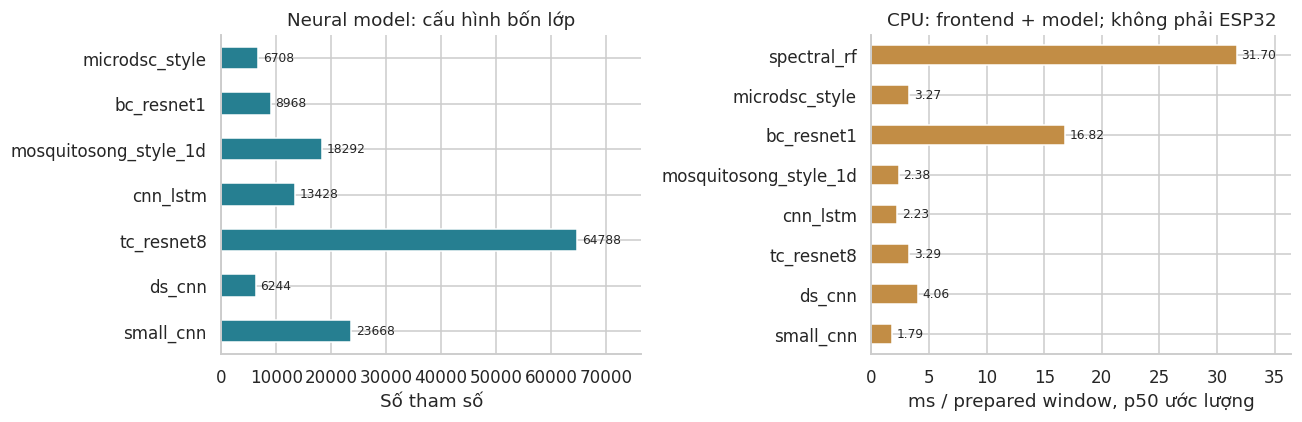

,model,input_shape,parameters,raw_weight_bytes,macs,largest_module_output_bytes,epochs_run,best_epoch,updates,fit_seconds,...,state,mode,device,threads,batch,frontend_p50_ms,model_p50_ms,model_p95_ms,prepared_window_total_p50_ms,repeats
0,small_cnn,"(1, 1, 40, 27)",23668,94672,2459776,69120,19,11,12426,167.251751,...,full_complete,full,cpu,4,1,0.335904,1.454092,1.675233,1.789996,20
1,ds_cnn,"(1, 1, 40, 27)",6244,24976,1550208,35840,11,3,7194,109.767603,...,full_complete,full,cpu,4,1,0.335904,3.723557,4.087549,4.059461,20
2,tc_resnet8,"(1, 1, 40, 27)",64788,259152,441024,1728,12,4,7848,123.613271,...,full_complete,full,cpu,4,1,0.335904,2.954692,3.572713,3.290596,20
3,cnn_lstm,"(1, 1, 40, 27)",13428,53712,1402880,69120,10,2,6540,91.722200,...,full_complete,full,cpu,4,1,0.335904,1.889875,2.145780,2.225779,20
4,mosquitosong_style_1d,"(1, 1, 2400)",18292,73168,4475776,76800,13,5,8502,136.749288,...,full_complete,full,cpu,4,1,0.009906,2.369187,2.576208,2.379094,20
5,bc_resnet1,"(1, 1, 40, 27)",8968,35872,663572,34560,13,5,8502,250.329240,...,full_complete,full,cpu,4,1,0.335904,16.480676,17.670467,16.816580,20
6,microdsc_style,"(1, 1, 40, 27)",6708,26832,404496,35840,13,5,8502,110.898942,...,full_complete,full,cpu,4,1,0.335904,2.929253,3.115311,3.265157,20


,model,mode,device,threads,batch,frontend_p50_ms,model_p50_ms,model_p95_ms,prepared_window_total_p50_ms,repeats
0,small_cnn,full,cpu,4,1,0.335904,1.454092,1.675233,1.789996,20
1,ds_cnn,full,cpu,4,1,0.335904,3.723557,4.087549,4.059461,20
2,tc_resnet8,full,cpu,4,1,0.335904,2.954692,3.572713,3.290596,20
3,cnn_lstm,full,cpu,4,1,0.335904,1.889875,2.145780,2.225779,20
4,mosquitosong_style_1d,full,cpu,4,1,0.009906,2.369187,2.576208,2.379094,20
5,bc_resnet1,full,cpu,4,1,0.335904,16.480676,17.670467,16.816580,20
6,microdsc_style,full,cpu,4,1,0.335904,2.929253,3.115311,3.265157,20
7,spectral_rf,full,cpu,4,1,1.311641,30.391222,34.212841,31.702864,20


,model,device,batch,p50_ms,p95_ms,repeats
0,small_cnn,cuda,1,0.657209,0.788603,20
1,ds_cnn,cuda,1,1.209825,1.352341,20
2,tc_resnet8,cuda,1,1.528104,2.461927,20
3,cnn_lstm,cuda,1,0.925022,1.025836,20
4,mosquitosong_style_1d,cuda,1,1.351116,1.534228,20
5,bc_resnet1,cuda,1,5.159689,5.465503,20
6,microdsc_style,cuda,1,1.982188,2.368296,20


In [20]:
verify_cell_source('B_latency')

def benchmark(function,warmup=5,repeats=20,device=None):
    for _ in range(warmup):function()
    if device is not None and device.type=='cuda':torch.cuda.synchronize(device)
    times=[]
    for _ in range(repeats):
        if device is not None and device.type=='cuda':torch.cuda.synchronize(device)
        started=time.perf_counter();function()
        if device is not None and device.type=='cuda':torch.cuda.synchronize(device)
        times.append((time.perf_counter()-started)*1000)
    return dict(p50_ms=float(np.median(times)),p95_ms=float(np.percentile(times,95)),repeats=repeats)
example_wave=read_window(active['train'].iloc[0]).copy()
def frontend_tensor(waveform=False):
    if waveform:
        x=((example_wave-float(statistics['raw_mean']))/float(statistics['raw_std'])).astype(np.float32)[None,None,:]
    else:
        x=((logmel(example_wave)-statistics['mel_mean'][:,None])/statistics['mel_std'][:,None])[None,None,:,:]
    return torch.from_numpy(np.array(x,dtype=np.float32,copy=True))
frontend_timing={key:benchmark(fn) for key,fn in dict(logmel=lambda:frontend_tensor(False),
    waveform=lambda:frontend_tensor(True),spectral_rf=lambda:spectral_features(example_wave)).items()}
latency_rows=[];accelerator_rows=[]
with torch.inference_mode():
    for name,model in trained_models.items():
        key='waveform' if name=='mosquitosong_style_1d' else 'logmel';tensor=frontend_tensor(key=='waveform')
        cpu_model=copy.deepcopy(model).cpu().eval()
        timing=benchmark(lambda:cpu_model(tensor))
        latency_rows.append(dict(model=name,mode=RUN_MODE,device='cpu',threads=CPU_THREADS,batch=1,
            frontend_p50_ms=frontend_timing[key]['p50_ms'],model_p50_ms=timing['p50_ms'],
            model_p95_ms=timing['p95_ms'],prepared_window_total_p50_ms=frontend_timing[key]['p50_ms']+timing['p50_ms'],repeats=timing['repeats']))
        del cpu_model
        if DEVICE.type=='cuda':
            model.eval();gpu_tensor=tensor.to(DEVICE)
            timing=benchmark(lambda:model(gpu_tensor),device=DEVICE)
            accelerator_rows.append(dict(model=name,device=str(DEVICE),batch=1,**timing))
rf_input=spectral_features(example_wave)[None,:]
with threadpool_limits(limits=CPU_THREADS):rf_timing=benchmark(lambda:rf.predict_proba(rf_input))
latency_rows.append(dict(model='spectral_rf',mode=RUN_MODE,device='cpu',threads=CPU_THREADS,batch=1,
    frontend_p50_ms=frontend_timing['spectral_rf']['p50_ms'],model_p50_ms=rf_timing['p50_ms'],
    model_p95_ms=rf_timing['p95_ms'],prepared_window_total_p50_ms=frontend_timing['spectral_rf']['p50_ms']+rf_timing['p50_ms'],repeats=rf_timing['repeats']))
latency=save_table(pd.DataFrame(latency_rows),'cpu_latency')
accelerator_latency=save_table(pd.DataFrame(accelerator_rows,columns=['model','device','batch','p50_ms','p95_ms','repeats']),'gpu_latency')
cost_summary=architectures.drop(columns='module_repr').merge(training_summary,on='model',validate='one_to_one').merge(latency,on='model',validate='one_to_one')
save_table(cost_summary,'neural_cost_summary')
machine=dict(platform=platform.platform(),processor=platform.processor(),torch_threads=torch.get_num_threads(),
    run_id=RUN_ID,git_commit=bootstrap_info['git_commit'],**compute_identity)
save_table(pd.DataFrame([dict(item=k,value=str(v)) for k,v in machine.items()]),'machine')
fig,axes=plt.subplots(1,2,figsize=(12,4))
architectures.set_index('model').parameters.plot.barh(ax=axes[0],color='#267f91')
axes[0].set_xlabel('Số tham số');axes[0].set_ylabel('');axes[0].set_title('Neural model: cấu hình bốn lớp')
axes[0].bar_label(axes[0].containers[0],fmt='%d',padding=3,fontsize=8)
axes[0].set_xlim(0,float(architectures.parameters.max())*1.18)
latency.set_index('model').prepared_window_total_p50_ms.plot.barh(ax=axes[1],color='#c28d45')
axes[1].set_xlabel('ms / prepared window, p50 ước lượng');axes[1].set_ylabel('');axes[1].set_title('CPU: frontend + model; không phải ESP32')
axes[1].bar_label(axes[1].containers[0],fmt='%.2f',padding=3,fontsize=8)
axes[1].set_xlim(0,float(latency.prepared_window_total_p50_ms.max())*1.15)
save_figure('06_cost')
display(cost_summary.drop(columns=['adaptation','best_model_sha256']));display(latency)
if len(accelerator_latency):display(accelerator_latency)


## 16. Kiểm tra cuối: metric, checkpoint, dữ liệu và test guard

Kiểm tra tín hiệu tổng hợp ở mục 4, train/backward trên audio thật, nạp model khớp xác suất, tổng hợp clip bằng ví dụ tính tay, cache shape và checksum A. Kiểm tra gọi lại lượt DS-CNN đã hoàn thành không thực hiện thêm update. Checkpoint mới có RNG CPU/CUDA và tiếp tục từ epoch đã lưu. Đây không phải kiểm chứng khả năng nhận dạng muỗi hoặc bảo đảm tái lập giữa các GPU/phiên bản.

In [21]:
verify_cell_source('B_checks')
checks=list(frontend_checks)
assert all(row['matched'] for row in waveform_checks)
def check(name,condition):
    checks.append(dict(check=name,passed=bool(condition))); assert condition,name
check('A_v1 và nhãn cố định',freeze['protocol_version']=='A_v1' and len(LABEL_NAMES)==4)
check('Train/validation không trùng clip',not set(active['train'].clip_id)&set(active['validation'].clip_id))
check('Không đọc audio test',not audio_accessed&test_clip_ids)
try:
    read_clip(sorted(test_clip_ids)[0]); guard=False
except ValueError: guard=True
check('Loader từ chối clip test trước I/O',guard and not audio_accessed&test_clip_ids)
check('Canonical thực đọc đúng hash A',len(audio_accessed)>0 and audio_accessed<=allowed_ids)
check('Thống kê fit đúng số window/sample training',int(statistics['fit_windows'])==len(active['train']) and
      int(statistics['fit_samples'])==len(active['train'])*WINDOW_SAMPLES)
expected_imputation=np.array([np.median(column[np.isfinite(column)]) if np.isfinite(column).any() else 0.
                              for column in arrays['train']['rf'].T])
check('RF imputer fit trên train',rf['imputer'].n_features_in_==len(FEATURE_NAMES) and
      np.allclose(rf['imputer'].statistics_,expected_imputation))
empty_feature_pipeline=SimpleImputer(strategy='median',keep_empty_features=True).fit(np.array([[1.,np.nan],[3.,np.nan]]))
check('Feature thiếu hoàn toàn vẫn giữ cột và transform hữu hạn',
      np.allclose(empty_feature_pipeline.transform([[np.nan,np.nan]]),[[2.,0.]]))
check('Đủ tám baseline và majority',set(predictions)==set(MODELS)|{'majority'})
check('Bảy neural model nạp lại đúng xác suất',len(serialization_checks)==len(NEURAL_MODELS)==7 and all(r['passed'] for r in serialization_checks))
check('MicroDSC pooling giữ kích thước hợp lệ cho 300ms',list(zip(microdsc_shapes.frequency,microdsc_shapes.time))==[(40,27),(20,14),(10,7),(5,3),(2,1),(1,1)])
check('MicroDSC đếm tham số cùng quy ước Keras khớp bản 11 lớp',microdsc_counts.iloc[-1].value==7483)
check('Có update gradient cho mọi neural model',training_summary.updates.gt(0).all())
check('Mọi mode đầu ra thống nhất',metrics['mode'].eq(RUN_MODE).all() and training_summary.state.eq(RUN_MODE+'_complete').all())
fake=pd.DataFrame(dict(window_id=['a0','a1','b0'],clip_id=['a','a','b'],label_id=[0,0,1],
    species=[LABEL_NAMES[0],LABEL_NAMES[0],LABEL_NAMES[1]],domain=['D1','D1','D2'],leakage_group=['a','a','b']))
aggregated=clip_probabilities(fake,np.array([[.6,.4,0,0],[.1,.9,0,0],[.1,.9,0,0]]))
check('Tổng hợp clip khớp trung bình xác suất tính tay',np.allclose(aggregated.loc[0,['p0','p1']].to_numpy(dtype=float),[.35,.65])
    and aggregated.prediction.tolist()==[1,1] and aggregated.windows.tolist()==[2,1])
last_before=sha(MODEL_DIR/'ds_cnn/last.pt')
_,completed_info=train_neural('ds_cnn')
check('Resume lượt hoàn tất không thêm update/đổi checkpoint',sha(MODEL_DIR/'ds_cnn/last.pt')==last_before and
      completed_info['updates']==int(training_summary.set_index('model').loc['ds_cnn','updates']))
for path,before in PROTECTED_BEFORE.items(): check('Không sửa '+str(path.relative_to(ROOT)),sha(path)==before)
if RUN_MODE=='smoke':
    check('Smoke không vượt ngân sách epoch/batch',training_summary.epochs_run.le(SMOKE_EPOCHS).all() and
          training_summary.updates.le(SMOKE_EPOCHS*SMOKE_MAX_BATCHES).all())
    full_after={str(p):sha(p) for p in (OUT/'full').rglob('*') if p.is_file()}
    check('Smoke không tạo/sửa kết quả full',full_after==FULL_ARTIFACTS_BEFORE)
check_results=save_table(pd.DataFrame(checks),'validation_checks')
save_table(pd.DataFrame([dict(clip_id=i,split=clip_lookup.loc[i,'split']) for i in sorted(audio_accessed)]),'audio_access_log')
display(check_results)
print('PASS:',len(check_results),'| Đã dùng',len(audio_accessed),'clip thực | Không có test scoring.')
check('Các cell chạy khớp source trên kernel',set(core_cells)-{'B_report'}<=verified_cell_tags)
check('Ánh xạ path chỉ có train/validation',set(clip_lookup.index)==allowed_ids and not set(clip_lookup.index)&test_clip_ids)
check('CPU latency là CPU cho mọi model',latency.device.eq('cpu').all())
check('GPU latency đủ neural khi dùng CUDA',len(accelerator_latency)==(len(NEURAL_MODELS) if DEVICE.type=='cuda' else 0))
check_results=save_table(pd.DataFrame(checks),'validation_checks')
save_table(pd.DataFrame(persistence_events,columns=['key','event','detail']),'persistence_events')
print('Tổng kiểm tra PASS:',len(check_results))


ds_cnn resume: 11 epoch; completed= True


,check,passed
0,Tone 500 Hz: peak PSD trong một bin,True
1,Tone 500 Hz: chu kỳ autocorrelation,True
2,Log-mel đúng 40 x 27,True
3,"Silence hữu hạn ở log-mel, F0 thiếu",True
4,"Gain x2: log-power tăng 6,02 dB trên vùng có n...",True
5,"Đỉnh tương quan âm: giữ window, chu kỳ thiếu v...",True
6,Audio hằng: không tạo chu kỳ giả,True
7,A_v1 và nhãn cố định,True
8,Train/validation không trùng clip,True
9,Không đọc audio test,True


PASS: 28 | Đã dùng 2090 clip thực | Không có test scoring.
Tổng kiểm tra PASS: 32


## 17. Report và bàn giao

Report có mode/run ID, dữ liệu thật đã dùng, mô tả frontend/kiến trúc, learning curves, metric chẩn đoán, chi phí, kiểm tra và giới hạn. Smoke không đề xuất model thắng. Không có dữ liệu full thì ghi rõ chưa có kết quả full. Manifest artifact chỉ kiểm các file cụ thể của lượt hiện tại, không đọc lại kết quả cũ rồi ghép vào run mới.

Sau khi xem smoke và quyết định chạy đầy đủ, dùng cùng notebook ở `RUN_MODE='full'`. Kết quả full lưu tách khỏi smoke; thời gian phụ thuộc runtime/model và early stopping. Colab lưu snapshot checkpoint lên Drive sau mỗi epoch; report cuối có bản HTML truy cập trực tiếp và snapshot ZIP. Các cải tiến sampling/loss/noise/gain/SupCon/distillation dành cho C–E.

In [22]:
verify_cell_source('B_report')
timestamp=datetime.now(ZoneInfo('Asia/Ho_Chi_Minh')).isoformat(timespec='seconds')
def frame_html(frame): return frame.to_html(index=False,border=0,float_format=lambda x:f'{x:,.4f}',escape=True)
def image_html(name,caption):
    payload=base64.b64encode((FIGURES/f'{name}.png').read_bytes()).decode()
    return f'<figure><img src="data:image/png;base64,{payload}" alt="{html.escape(caption)}"><figcaption>{html.escape(caption)}</figcaption></figure>'
def bullets(items): return '<ul>'+''.join('<li>'+html.escape(str(x))+'</li>' for x in items)+'</ul>'
limitations=[
    'A_v1 là thí nghiệm chuyển domain theo từng loài, không phải domain hoàn toàn chưa xuất hiện trong toàn training.',
    'Albopictus validation chỉ một nguồn D1; trong pool A có 67 clip đủ window và 164 window. Nhiều clip/seed không tạo thêm nguồn độc lập. Thứ hạng validation chưa chắc ổn định.',
    'Dirus train/validation chỉ D1 và ít window train nhất; minimus có khoảng 80% window train từ D4.',
    'Nguồn/cá thể và loại cảm biến chưa xác minh cho mọi clip, đặc biệt D5. Chưa chứng minh microphone-only hoặc chuyển được sang INMP441.',
    'Window kế thừa nhãn clip, không bảo đảm mỗi window có wingbeat rõ. Chưa phân loại giới tính, phát hiện muỗi/nền hoặc hiệu chuẩn uncertain.',
    'Điểm paper, source macro-F1 project cũ và clip macro-F1 A_v1 không được so trực tiếp.',
    'MAC chỉ gồm Conv/Linear/LSTM; output module lớn nhất không phải peak RAM. CPU latency dùng bản sao model trên CPU. GPU latency (nếu có) có synchronize, chỉ model trên tensor sẵn GPU; chưa gồm copy H2D/thu âm/I/O/resample. Cả hai không thay kết quả ESP32-S3.',
    'Một recipe chung không bảo đảm mọi kiến trúc đã được tối ưu như nhau. Waveform và MicroDSC-style đều là bản thích nghi, không phải tái lập nguyên paper.',
    'MicroDSC-style dùng log-mel 40×27/300ms, không dùng MFE 5 giây của paper. Sau ba pool còn 2×1 trước GAP; cần full validation để kiểm tra mất thông tin theo thời gian. Chưa lượng tử hóa hoặc đo trên ESP32-S3.']
notice=('SMOKE TEST — CHƯA CÓ KẾT QUẢ BASELINE ĐẦY ĐỦ. Metric dưới đây chỉ kiểm tra code, '
        'không xếp hạng model; clip smoke chỉ gộp các window được chọn.' if RUN_MODE=='smoke' else
        'FULL BASELINE — một seed, chỉ train/validation. Chưa đánh giá test; lưu ý validation albopictus chỉ một nguồn.')
assert set(core_cells)<=verified_cell_tags
shutil.copyfile(NOTEBOOK_PATH,RUN_OUT/'source_notebook.ipynb')
run_status=save_table(pd.DataFrame([dict(mode=RUN_MODE,run_id=RUN_ID,status=RUN_MODE+'_complete',
    timestamp=timestamp,train_windows=len(active['train']),validation_windows=len(active['validation']),
    audio_test_reads=0,test_predictions=0,checks_passed=len(check_results),
    full_baselines_run=(RUN_MODE=='full'))]),'run_status')
status_display=pd.DataFrame([
    ('Chế độ',RUN_MODE),('Trạng thái',RUN_MODE+'_complete'),
    ('Neural training device',str(DEVICE)),('RF/frontend device','CPU'),
    ('Persistent Drive folder',str(PERSIST_DIR) if PERSIST_ENABLED else 'local only'),
    ('Window train / validation',f"{len(active['train'])} / {len(active['validation'])}"),
    ('Clip thực đã đọc',len(audio_accessed)),('Kiểm tra PASS',len(check_results)),
    ('Audio test đã đọc / dự đoán test','0 / 0'),
    ('Baseline đầy đủ đã chạy','Có' if RUN_MODE=='full' else 'Chưa'),
    ('Run ID',RUN_ID)],columns=['Nội dung','Giá trị'])
artifact_files=[p for folder in [TABLES,FIGURES,MODEL_DIR] for p in folder.rglob('*')
                if p.is_file() and p.name!='artifacts.csv' and not p.name.endswith('.tmp')]+[RUN_OUT/'source_notebook.ipynb']
artifacts=save_table(pd.DataFrame([dict(path=str(p.relative_to(ROOT)),bytes=p.stat().st_size,
    sha256=sha(p),run_id=RUN_ID,mode=RUN_MODE) for p in sorted(artifact_files)]),'artifacts')
for row in artifacts.itertuples(): assert sha(ROOT/row.path)==row.sha256
license_md=next(c.source for c in nb_source.cells if c.cell_type=='markdown' and 'Copyright (c) 2023 Qualcomm' in c.source)
license_text=license_md[license_md.index('Copyright (c) 2023 Qualcomm'):license_md.index('</details>')]
sections=[f'<h1>B — Tám baseline / {RUN_MODE}</h1>',
    f'<p class="meta">{html.escape(timestamp)} · Run ID {RUN_ID[:12]}</p>',
    '<div class="notice">'+html.escape(notice)+'</div>',
    '<h2>1. Dữ liệu và phạm vi</h2>',frame_html(status_display),frame_html(selected_counts),
    '<p>Đã xác minh checksum A_v1, chỉ đọc audio train/validation. Không thay split, không train/test tuning. Full pool từ A được ghi để đối chiếu:</p>',frame_html(coverage),
    image_html('02_selected_windows','Số window thực dùng trong chế độ hiện tại.'),
    '<h2>2. Đầu vào và chuẩn hóa</h2>',frame_html(pd.DataFrame([dict(item=k,value=str(v)) for k,v in frontend_settings.items() if k!='feature_names'])),
    '<p>Log-mel mean/std theo bin và waveform mean/std toàn cục chỉ fit trên training của chế độ hiện tại. RF imputer fit trong pipeline trên train; F0 là candidate periodicity có thể thiếu/sai octave.</p>',
    image_html('01_inputs','Ví dụ window training, dùng chung quy trình với loader.'),
    '<h2>3. Kiến trúc và thay đổi</h2>',frame_html(architectures.drop(columns='module_repr')),
    '<h3>Enhanced MicroDSC-style: theo dõi kích thước và cách đếm tham số</h3>',
    '<p>Stem 16, block 32/48/64; ReLU6; ba pool 2×2; GAP và head bốn lớp. BN epsilon 0,001/momentum PyTorch 0,01; stem giữ TensorFlow SAME. Dùng frontend và recipe B, khởi tạo PyTorch; không tái lập nguyên bài báo. Parameters trong bảng kiến trúc là trainable; 7.483 của reference gồm BN moving statistics và head 11 lớp. Không tính num_batches_tracked vào đối chiếu Keras.</p>',
    frame_html(microdsc_shapes),frame_html(microdsc_counts),frame_html(microdsc_reference),
    '<h2>4. Kiểm tra huấn luyện và checkpoint</h2>',frame_html(training_summary.drop(columns='best_model_sha256')),
    image_html('03_learning_curves','Smoke giới hạn batch/epoch, không phải kết quả hội tụ.' if RUN_MODE=='smoke' else 'Đường học baseline.'),
    '<h2>5. Metric train/validation — '+('chẩn đoán smoke' if RUN_MODE=='smoke' else 'baseline một seed')+'</h2>',
    frame_html(metrics),frame_html(per_class.loc[per_class.level.eq('clip')]),
    image_html('04_validation_confusion','Confusion cấp clip: tỷ lệ theo hàng và số clip.'),
    image_html('05_validation_recall','Recall validation theo loài, có support trong bảng.'),frame_html(domain_metrics),
    '<h2>6. Chi phí trên máy đang chạy</h2>',
    '<p>CPU: frontend + bản sao model CPU. GPU (nếu dùng): tensor đã ở GPU, synchronize trước/sau đo, chưa tính H2D. Hai bảng không dùng để suy ra latency ESP32-S3.</p>',
    frame_html(latency),frame_html(accelerator_latency),frame_html(pd.DataFrame([rf_stats])),frame_html(pd.DataFrame([dict(item=k,value=str(v)) for k,v in machine.items()])),
    image_html('06_cost','Số tham số và latency CPU; chưa phải tài nguyên triển khai trên board.'),
    '<h2>7. Kiểm tra và khả năng truy vết</h2>',frame_html(check_results),
    '<p>Cấu hình: tables/run_settings.csv; input/output hash: tables/artifacts.csv; source: source_notebook.ipynb. Cell thực thi đối chiếu với code trên kernel. Checkpoint format 2 có RNG CPU/CUDA, optimizer và selected weights; tiếp tục từ epoch đã lưu. Artifact inventory không tự chứng minh chất lượng phân loại.</p>',
    frame_html(pd.DataFrame(persistence_events,columns=['key','event','detail'])),
    '<h2>8. Giới hạn và bước tiếp theo</h2>',bullets(limitations),
    '<p>'+('Chỉ hoàn tất code và smoke theo phê duyệt. Chưa chọn model tốt nhất. Sau khi smoke trên runtime được kiểm tra, người dùng chủ động chọn full. Chưa tự chạy thêm hoặc đánh giá test.' if RUN_MODE=='smoke' else
             'Chọn shortlist có cân nhắc chất lượng từng loài/chi phí; C mới kiểm tra từng thay đổi. F đánh giá test sau khi chốt phương pháp.')+'</p>',
    '<h2>9. Nguồn, ghi công và giấy phép</h2>',
    '<p><a href="https://arxiv.org/pdf/1711.07128">DS-CNN</a> · <a href="https://www.isca-archive.org/interspeech_2019/choi19_interspeech.pdf">TC-ResNet</a> · <a href="https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0310121">MosquitoSong+</a> · <a href="https://github.com/Qualcomm-AI-research/bcresnet">BC-ResNet</a>. Các điểm công bố không phải điểm A_v1.</p>',
    '<p>Enhanced MicroDSC: Micheline Kazeneza và các đồng tác giả (2026), <a href="https://doi.org/10.7717/peerj-cs.3925">paper</a>, <a href="https://doi.org/10.5281/zenodo.18879243">code v1.0.0</a>, <a href="https://creativecommons.org/licenses/by/4.0/">CC BY 4.0</a>. Bản PyTorch đã thay frontend, đầu ra và recipe; nguồn/version/hash ở tables/microdsc_reference.csv.</p>',
    '<pre class="license">'+html.escape(license_text)+'</pre>']
css='body{font-family:Segoe UI,Arial,sans-serif;max-width:1200px;margin:32px auto;padding:0 24px;color:#23343a;line-height:1.6}h1,h2{color:#15576b;line-height:1.3}h2{margin-top:36px}.notice{padding:20px;background:#fff2d8;border-left:5px solid #b87913;font-weight:600}table{display:block;overflow-x:auto;max-width:100%;border-collapse:collapse;font-size:13px;margin:18px 0}th,td{padding:8px 10px;border-bottom:1px solid #dce5e8;text-align:left;vertical-align:top;overflow-wrap:anywhere}th{background:#eef5f7;white-space:nowrap}td{min-width:70px;max-width:420px}img{width:100%;height:auto}figure{margin:22px 0}figcaption,.meta{font-size:13px;color:#52636a}.license{white-space:pre-wrap;overflow-wrap:anywhere;font-size:12px}li{margin-bottom:7px}'
report='<!doctype html><html lang="vi"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1"><title>B — '+RUN_MODE+' baseline</title><style>'+css+'</style></head><body>'+''.join(sections)+'</body></html>'
(RUN_OUT/'report.html').write_text(report,encoding='utf-8')
index_sections=['<h1>B — Trạng thái baseline</h1>',
    '<p>Smoke chỉ kiểm tra code; full mới có kết quả baseline để thảo luận. Các chế độ lưu riêng, test chưa được đánh giá trong B.</p>']
for mode in ['smoke','full']:
    if (OUT/mode/'report.html').exists(): index_sections.append(f'<p><a href="{mode}/report.html">Mở report {mode}</a></p>')
    else: index_sections.append(f'<p>{mode}: chưa có report.</p>')
(OUT/'report.html').write_text('<!doctype html><html lang="vi"><meta charset="utf-8"><title>B — Trạng thái</title><style>'+css+'</style><body>'+''.join(index_sections)+'</body></html>',encoding='utf-8')
print('Report:',RUN_OUT/'report.html')
print('Trạng thái:',RUN_MODE+'_complete','| Chưa có test scoring.')
if PERSIST_ENABLED:
    report_files=[p for base in [TABLES,FIGURES,MODEL_DIR] for p in base.rglob('*') if p.is_file() and not p.name.endswith('.tmp')]
    report_files += [RUN_OUT/'report.html',RUN_OUT/'source_notebook.ipynb']
    prior=checked_snapshot('report')
    if prior:snapshot_generation['report']=prior[0]
    save_snapshot('report',report_files,len(NEURAL_MODELS))
    # Human-readable report stays directly accessible; the verified ZIP is the durable snapshot.
    shutil.copyfile(RUN_OUT/'report.html',PERSIST_DIR/'report.html')
    print('Đã lưu checkpoint và report trên Drive:',PERSIST_DIR)


Report: /content/Edge_AI_Mosquito/results/B/baseline_v1/full/io_v2/report.html
Trạng thái: full_complete | Chưa có test scoring.
Đã lưu checkpoint và report trên Drive: /content/drive/MyDrive/Edge_AI_Mosquito/runs/B/baseline_v1/full/b67e5bff23cad061
